# stoX Quantitative Engine — Proof of Concept

Companion notebook to `stoX_quantitative_engine_spec.md`. It implements both analytical tracks of the stoX platform
for the US market and the Saudi Exchange (TASI):

| Track | What it does | Sections |
|---|---|---|
| **A. Day-Trading Engine** | Intraday factors → cross-sectional composite rank → top 3–5 basket → ORB backtest | 3, 4 |
| **B. Long-Term Engine** | 30-point 5-axis scorecard, Altman Z/Z′, Target-Yield vs DCF fair value, filing sentiment | 5, 6, 7 |

**Compliance:** stoX is *descriptive analytics only*. Nothing here is a recommendation to buy or sell.
Outputs are screening statistics, not investment advice.

**Data modes.** The notebook downloads real data with `yfinance`. If a download fails (offline, rate-limited, no
intraday history for a `.SR` ticker) that ticker falls back to **clearly-labelled synthetic or illustrative data** so the
whole notebook still runs end-to-end. The data source of every ticker is printed — always check it before
interpreting any number. Backtest results on synthetic data carry no information about real markets.

**Setup:** `pip install pandas numpy matplotlib yfinance` (Python 3.8+). Run the cells top to bottom.

> **Update:** Part 2 (sections 9-15) was appended at the end of this notebook: ML stock ranking, multi-timeframe factors,
> the daily tracking log and the quarterly report. Sections 0-8 are unchanged. Extra dependency: `pip install scikit-learn`.

In [2]:
from __future__ import annotations

import json
import re
import warnings
import zlib
from dataclasses import asdict, dataclass, field, replace
from datetime import datetime, timezone
from typing import Dict, List, Optional, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

try:
    import yfinance as yf
except ImportError:  # the notebook still runs on fallback data
    yf = None

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)

FORCE_FALLBACK_DATA = False  # True = skip the network entirely (deterministic demo)
OHLCV = ["Open", "High", "Low", "Close", "Volume"]

## 1. Environment, markets and configuration

All tunable parameters live in two places: `DayTradingConfig` (Track A) and `MARKET_ASSUMPTIONS` (Track B).
Percentages are expressed in **percent units** (2.5 means +2.5 %) for Track A factors and as **fractions** (0.05 = 5 %)
in Track B ratios, matching the formulas in the specification.

In [5]:
@dataclass(frozen=True)
class Market:
    name: str
    tz: str
    open_time: str    # regular session start, local time
    close_time: str   # regular session end, local time
    has_extended_hours: bool


US = Market("US", "America/New_York", "09:30", "16:00", has_extended_hours=True)
TASI = Market("TASI", "Asia/Riyadh", "10:00", "15:00", has_extended_hours=False)

US_TICKERS = ["NVDA", "TSLA", "AMD", "AAPL", "MSFT"]
TASI_TICKERS = ["2082.SR", "7200.SR", "2222.SR"]
ALL_TICKERS = US_TICKERS + TASI_TICKERS


def market_of(ticker: str) -> Market:
    return TASI if ticker.endswith(".SR") else US


@dataclass(frozen=True)
class DayTradingConfig:
    # sessions and look-backs
    bar_minutes: int = 5
    orb_minutes: int = 30           # opening range; signals are computed when it completes
    lookback_days: int = 20         # RVOL baseline, spread averaging
    atr_days: int = 14
    # ranking
    top_k: int = 3                  # basket size, must be 3..5
    weights: Dict[str, float] = field(default_factory=lambda: {
        "rvol": 0.25, "atr_pct": 0.15, "vwap_dev_pct": 0.15, "gap_score": 0.15,
        "roc_pct": 0.10, "accel_pct": 0.05, "overnight_break": 0.10, "overnight_vol_ratio": 0.05,
    })
    gap_band: Tuple[float, float] = (1.0, 2.5)   # % — continuation band
    gap_fade_scale: float = 2.5                  # % beyond the band at which the gap score reaches 0
    spread_tolerance_pct: float = 0.40           # % — penalty starts above this estimated (high-low proxy) spread
    spread_lambda: float = 0.5                   # penalty strength (score units per 100 % excess over tolerance)
    # hard eligibility filters
    min_atr_pct: float = 2.0
    min_rvol: float = 1.0
    max_spread_pct: float = 1.00
    # trade simulation
    target_pct: float = 2.5
    stop_pct: float = 1.2
    round_trip_cost_pct: float = 0.10


CFG = DayTradingConfig()
assert abs(sum(CFG.weights.values()) - 1.0) < 1e-9 and 3 <= CFG.top_k <= 5

## 2. Data ingestion module

* **Intraday (Track A):** 5-minute OHLCV bars (≈55 days, the Yahoo limit is 60). US tickers include pre-/post-market
  bars (`prepost=True`), which feed the overnight factors. Timestamps are converted to the exchange's local time.
  **Yahoo reports zero volume for extended-hours bars**, so `overnight_vol_ratio` is inert (constant 0) on this feed;
  the overnight *price* break still works. A real overnight/pre-market volume feed is required to activate it.
* **Fallback:** a seeded synthetic generator (random-walk prices, U-shaped volume, gaps, pre-market bars for US).
* **Fundamentals (Track B):** annual statements via `yfinance`; falls back to illustrative fixtures (section 5).

In [6]:
def download_intraday(ticker: str, market: Market, days: int = 55) -> pd.DataFrame:
    """5-minute OHLCV in exchange-local time; extended hours included where the market has them."""
    raw = yf.download(ticker, period=f"{days}d", interval="5m", prepost=market.has_extended_hours,
                      progress=False, auto_adjust=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    bars = raw[OHLCV].dropna()
    if bars.empty:
        raise ValueError(f"no intraday data returned for {ticker}")
    index = bars.index.tz_localize("UTC") if bars.index.tz is None else bars.index
    bars.index = index.tz_convert(market.tz)
    return bars


def _random_bars(timestamps: pd.DatetimeIndex, start_price: float, bar_sigma: float,
                 volume_scale: float, rng: np.random.Generator) -> pd.DataFrame:
    """Random-walk OHLCV bars with a U-shaped intraday volume profile."""
    n = len(timestamps)
    closes = start_price * np.exp(np.cumsum(rng.normal(0, bar_sigma, n)))
    opens = np.r_[start_price, closes[:-1]]
    wick = np.abs(rng.normal(0, bar_sigma / 2, n))
    u_shape = 1 + 2 * np.linspace(-1, 1, n) ** 2
    return pd.DataFrame({
        "Open": opens,
        "High": np.maximum(opens, closes) * (1 + wick),
        "Low": np.minimum(opens, closes) * (1 - wick),
        "Close": closes,
        "Volume": volume_scale * u_shape * rng.lognormal(0, 0.4, n),
    }, index=timestamps)


def synthetic_intraday(ticker: str, market: Market, days: int = 45, bar_minutes: int = 5) -> pd.DataFrame:
    """Deterministic (seeded by ticker) stand-in for real intraday data. Contains NO market information."""
    rng = np.random.default_rng(zlib.crc32(ticker.encode()))
    weekmask = "Sun Mon Tue Wed Thu" if market is TASI else "Mon Tue Wed Thu Fri"
    dates = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=days, freq="C", weekmask=weekmask)
    freq = f"{bar_minutes}min"
    price, frames = rng.uniform(40, 400), []
    for date in dates:
        day = date.strftime("%Y-%m-%d")
        regular_ts = pd.date_range(f"{day} {market.open_time}", f"{day} {market.close_time}",
                                   freq=freq, tz=market.tz, inclusive="left")
        daily_sigma = 0.02 * rng.lognormal(0, 0.3)
        bar_sigma = daily_sigma / np.sqrt(len(regular_ts))
        volume_scale = 1e6 / len(regular_ts) * rng.lognormal(0, 0.3)
        day_start = price * (1 + rng.standard_t(3) * 0.006)               # overnight gap
        if market.has_extended_hours:
            pre_ts = pd.date_range(f"{day} 04:00", f"{day} {market.open_time}", freq=freq,
                                   tz=market.tz, inclusive="left")
            pre = _random_bars(pre_ts, day_start, bar_sigma * 0.5, volume_scale * 0.05, rng)
            frames.append(pre)
            day_start = pre["Close"].iloc[-1]
        regular = _random_bars(regular_ts, day_start, bar_sigma, volume_scale, rng)
        frames.append(regular)
        price = regular["Close"].iloc[-1]
    return pd.concat(frames)


def load_market_data(tickers: List[str]) -> Tuple[Dict[str, pd.DataFrame], Dict[str, str]]:
    """Download intraday bars per ticker; fall back to synthetic bars on any failure."""
    data, sources = {}, {}
    for ticker in tickers:
        market = market_of(ticker)
        try:
            if yf is None or FORCE_FALLBACK_DATA:
                raise ImportError("yfinance unavailable or fallback forced")
            data[ticker], sources[ticker] = download_intraday(ticker, market), "yfinance (real)"
        except Exception as exc:
            data[ticker] = synthetic_intraday(ticker, market, bar_minutes=CFG.bar_minutes)
            sources[ticker] = f"SYNTHETIC ({type(exc).__name__})"
    return data, sources


intraday, data_sources = load_market_data(ALL_TICKERS)
display(pd.DataFrame({
    "source": pd.Series(data_sources),
    "bars": pd.Series({t: len(b) for t, b in intraday.items()}),
    "first": pd.Series({t: b.index[0].strftime("%Y-%m-%d") for t, b in intraday.items()}),
    "last": pd.Series({t: b.index[-1].strftime("%Y-%m-%d") for t, b in intraday.items()}),
}))

,source,bars,first,last
NVDA,yfinance (real),10312,2026-07-31,2026-10-16
TSLA,yfinance (real),10308,2026-07-31,2026-10-16
AMD,yfinance (real),10275,2026-07-31,2026-10-16
AAPL,yfinance (real),10308,2026-07-31,2026-10-16
MSFT,yfinance (real),10271,2026-07-31,2026-10-16
2082.SR,yfinance (real),3261,2026-08-02,2026-10-18
7200.SR,yfinance (real),3168,2026-08-02,2026-10-18
2222.SR,yfinance (real),3261,2026-08-02,2026-10-18


## 3. Day-trading engine — factors, composite ranking, top 3–5 selection

**Pipeline:** raw bars → per-day *sessions* (regular bars + the extended-hours window before the open) →
one summary row per day → factor table → cross-sectional ranking.

**No look-ahead:** every factor is available at the *signal time* = end of the opening range (default 30 min
after the open). Baselines (ATR, 20-day averages) use prior days only (`shift(1)`). Trades can only start after the signal time.

In [7]:
@dataclass
class Session:
    date: pd.Timestamp          # exchange-local trading date (tz-naive)
    bars: pd.DataFrame          # regular-session bars
    overnight: pd.DataFrame     # extended-hours bars between previous close and this open (may be empty)


def _minutes(hhmm: str) -> int:
    hours, minutes = hhmm.split(":")
    return int(hours) * 60 + int(minutes)


def build_sessions(bars: pd.DataFrame, market: Market, bar_minutes: int) -> List[Session]:
    """Split a bar stream into complete regular sessions plus the extended-hours window preceding each open."""
    minute_of_day = bars.index.hour * 60 + bars.index.minute
    is_regular = (minute_of_day >= _minutes(market.open_time)) & (minute_of_day < _minutes(market.close_time))
    regular, extended = bars[is_regular], bars[~is_regular]
    expected_bars = (_minutes(market.close_time) - _minutes(market.open_time)) // bar_minutes

    days = [day for _, day in regular.groupby(regular.index.normalize())]
    opens = pd.DatetimeIndex([day.index[0] for day in days])
    next_open_slot = opens.searchsorted(extended.index, side="right")   # extended bar -> the open it precedes

    sessions = []
    for slot, day in enumerate(days):
        if len(day) >= 0.8 * expected_bars:                              # skip holidays / half days / gaps
            sessions.append(Session(pd.Timestamp(day.index[0].date()), day, extended[next_open_slot == slot]))
    return sessions


def summarise_session(session: Session, cfg: DayTradingConfig) -> dict:
    """Collapse one session into the raw quantities the factors are built from."""
    bars, overnight = session.bars, session.overnight
    n_orb = cfg.orb_minutes // cfg.bar_minutes
    orb = bars.iloc[:n_orb]
    typical_price = (orb["High"] + orb["Low"] + orb["Close"]) / 3
    return {
        "date": session.date,
        "open": bars["Open"].iloc[0], "high": bars["High"].max(),
        "low": bars["Low"].min(), "close": bars["Close"].iloc[-1],
        "orb_volume": orb["Volume"].sum(),
        "orb_vwap": (typical_price * orb["Volume"]).sum() / orb["Volume"].sum(),
        "early_price": orb["Close"].iloc[n_orb // 2 - 1],      # midpoint of the opening range
        "signal_price": orb["Close"].iloc[-1],                 # last price known at signal time
        "overnight_high": overnight["High"].max(), "overnight_low": overnight["Low"].min(),
        "overnight_volume": overnight["Volume"].sum(),
    }


def corwin_schultz_spread(high: pd.Series, low: pd.Series) -> pd.Series:
    """High-low bid-ask spread estimator (Corwin & Schultz, 2012) as a fraction of price.

    Yahoo has no historical quotes, so the quoted spread is proxied from daily highs and lows.
    """
    k = 3 - 2 * np.sqrt(2)
    hl2 = np.log(high / low) ** 2
    beta = hl2 + hl2.shift(1)
    gamma = np.log(np.maximum(high, high.shift(1)) / np.minimum(low, low.shift(1))) ** 2
    alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / k - np.sqrt(gamma / k)
    return (2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))).clip(lower=0)


def compute_factors(daily: pd.DataFrame, cfg: DayTradingConfig) -> pd.DataFrame:
    """Factor table for one ticker (one row per session, all values known at signal time)."""
    prev_close = daily["close"].shift(1)
    true_range = pd.concat([daily["high"] - daily["low"],
                            (daily["high"] - prev_close).abs(),
                            (daily["low"] - prev_close).abs()], axis=1).max(axis=1)
    atr = true_range.rolling(cfg.atr_days).mean().shift(1)

    def prior_mean(series: pd.Series) -> pd.Series:           # mean of the previous `lookback_days` sessions
        return series.shift(1).rolling(cfg.lookback_days).mean()

    early_roc = daily["early_price"] / daily["open"] - 1
    late_roc = daily["signal_price"] / daily["early_price"] - 1
    overnight_ratio = (daily["overnight_volume"] / prior_mean(daily["overnight_volume"]))

    return pd.DataFrame({
        "rvol": daily["orb_volume"] / prior_mean(daily["orb_volume"]),
        "atr_pct": atr / prev_close * 100,
        "gap_pct": (daily["open"] / prev_close - 1) * 100,
        "vwap_dev_pct": (daily["signal_price"] / daily["orb_vwap"] - 1) * 100,
        "roc_pct": (daily["signal_price"] / daily["open"] - 1) * 100,
        "accel_pct": (late_roc - early_roc) * 100,           # change in velocity across the opening range
        "spread_pct": prior_mean(corwin_schultz_spread(daily["high"], daily["low"])) * 100,
        "overnight_vol_ratio": overnight_ratio.replace([np.inf, -np.inf], np.nan).fillna(0.0),
        "overnight_break": np.where(daily["signal_price"] > daily["overnight_high"], 1,
                                    np.where(daily["signal_price"] < daily["overnight_low"], -1, 0)),
    })


CORE_FACTORS = ["rvol", "atr_pct", "gap_pct", "vwap_dev_pct", "roc_pct", "accel_pct", "spread_pct"]


def build_feature_table(sessions: Dict[str, List[Session]], cfg: DayTradingConfig) -> pd.DataFrame:
    """Stack every ticker's factors into one (date, ticker)-indexed table."""
    tables = []
    for ticker, ticker_sessions in sessions.items():
        daily = pd.DataFrame([summarise_session(s, cfg) for s in ticker_sessions]).set_index("date")
        factors = compute_factors(daily, cfg)
        factors["ticker"], factors["market"] = ticker, market_of(ticker).name
        tables.append(factors)
    features = pd.concat(tables).dropna(subset=CORE_FACTORS)
    features.index.name = "date"
    return features.reset_index().set_index(["date", "ticker"]).sort_index()


sessions = {t: build_sessions(bars, market_of(t), CFG.bar_minutes) for t, bars in intraday.items()}
features = build_feature_table(sessions, CFG)
display(features.tail(8))

rvol  atr_pct  gap_pct  vwap_dev_pct  roc_pct  accel_pct  spread_pct  overnight_vol_ratio  overnight_break market
date       ticker                                                                                                                   
2026-10-15 MSFT   1.033    2.273   -0.040         0.027    0.201     -0.531       0.520                0.000                1     US
           NVDA   1.756    2.526   -2.781        -0.141   -0.585     -0.793       0.338                0.000               -1     US
           TSLA   0.722    2.978   -1.832        -0.707   -1.328     -0.942       0.186                0.000               -1     US
2026-10-16 AAPL   2.499    1.895    1.221        -0.060   -0.367      1.072       0.405                0.000                0     US
           AMD    0.796    4.648   -2.459        -0.695   -1.126     -0.974       0.606                0.000               -1     US
           MSFT   1.166    2.088    0.321        -0.439   -0.642      0.733       0.565                0.000                0     US
           NVDA   1.067    2.735   -0.313         0.088   -0.139      0.034       0.338                0.000                0     US
           TSLA   2.197    2.877    1.779        -0.098   -0.623     -0.522       0.186                0.000                0     US


=== TASI — basket for 2026-10-15 (selected = top 3) ===


,rank,ticker,score,eligible,selected,relaxed,rvol,atr_pct,gap_pct,vwap_dev_pct,roc_pct,spread_pct,spread_penalty
256,1,2082.SR,-0.053,True,True,False,1.447,2.878,-0.374,-0.593,-1.313,0.545,0.182
257,2,2222.SR,-0.281,False,True,True,1.186,1.094,-0.628,-0.066,-0.079,0.178,0.000
258,3,7200.SR,-0.920,False,True,True,1.246,3.173,0.133,-0.432,-1.592,1.258,1.072



=== US — basket for 2026-10-16 (selected = top 3) ===


,rank,ticker,score,eligible,selected,relaxed,rvol,atr_pct,gap_pct,vwap_dev_pct,roc_pct,spread_pct,spread_penalty
264,1,TSLA,0.497,True,True,False,2.197,2.877,1.779,-0.098,-0.623,0.186,0.000
265,2,NVDA,0.005,True,True,False,1.067,2.735,-0.313,0.088,-0.139,0.338,0.000
266,3,MSFT,-0.541,True,True,False,1.166,2.088,0.321,-0.439,-0.642,0.565,0.206
267,4,AAPL,0.653,False,False,False,2.499,1.895,1.221,-0.060,-0.367,0.405,0.007
268,5,AMD,-1.086,False,False,False,0.796,4.648,-2.459,-0.695,-1.126,0.606,0.258


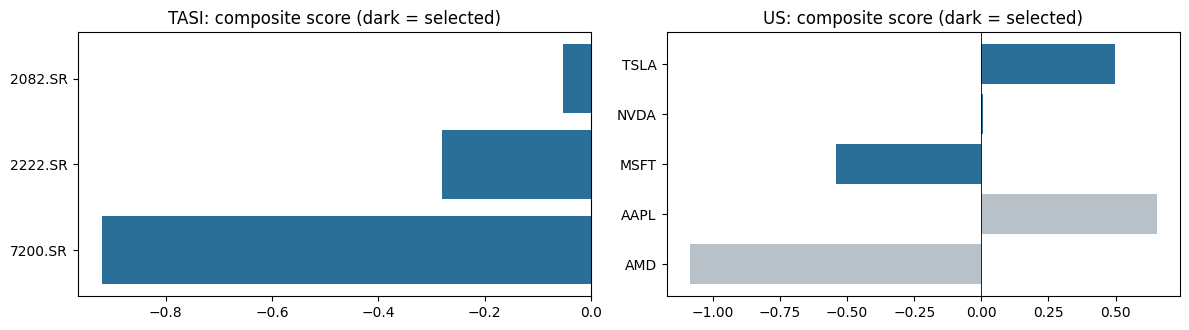

In [9]:
def gap_score(gap_pct: float, band: Tuple[float, float], fade_scale: float) -> float:
    """Long-side gap quality in [0, 1]: ramps up to the continuation band, flat inside it, decays beyond (fade risk)."""
    low, high = band
    if gap_pct <= 0:
        return 0.0
    if gap_pct < low:
        return gap_pct / low
    if gap_pct <= high:
        return 1.0
    return max(0.0, 1.0 - (gap_pct - high) / fade_scale)


def zscore(values: pd.Series) -> pd.Series:
    """Cross-sectional z-score; a constant column (no information) scores 0 for everyone."""
    std = values.std(ddof=0)
    return (values - values.mean()) / std if std > 0 else values * 0.0


def rank_session(group: pd.DataFrame, cfg: DayTradingConfig) -> pd.DataFrame:
    """Score and rank one market's universe for one trading date.

    score = sum_i w_i * z(factor_i)  -  lambda * max(0, spread - tolerance) / tolerance
    Order: eligible names first, then score, then RVOL, then ATR%, then ticker (A->Z) — fully deterministic.
    """
    g = group.copy()
    g["gap_score"] = g["gap_pct"].apply(gap_score, args=(cfg.gap_band, cfg.gap_fade_scale))
    z = g[list(cfg.weights)].apply(zscore)
    g["raw_score"] = sum(weight * z[factor] for factor, weight in cfg.weights.items())
    g["spread_penalty"] = (cfg.spread_lambda * (g["spread_pct"] - cfg.spread_tolerance_pct).clip(lower=0)
                           / cfg.spread_tolerance_pct)
    g["score"] = (g["raw_score"] - g["spread_penalty"]).round(6)   # rounding stops float noise deciding ties
    g["eligible"] = ((g["atr_pct"] >= cfg.min_atr_pct) & (g["rvol"] >= cfg.min_rvol)
                     & (g["spread_pct"] <= cfg.max_spread_pct))

    g = g.sort_values(["eligible", "score", "rvol", "atr_pct", "ticker"],
                      ascending=[False, False, False, False, True]).reset_index(drop=True)
    g["rank"] = np.arange(1, len(g) + 1)
    g["selected"] = g["rank"] <= cfg.top_k                    # basket is always top_k (or the whole universe if smaller)
    g["relaxed"] = g["selected"] & ~g["eligible"]             # filled from ineligible names when too few pass the filters
    return g


def build_baskets(features: pd.DataFrame, cfg: DayTradingConfig) -> pd.DataFrame:
    """Rank every (date, market) group; markets are ranked separately because they trade different sessions."""
    flat = features.reset_index()
    return pd.concat([rank_session(group, cfg) for _, group in flat.groupby(["date", "market"])],
                     ignore_index=True)


baskets = build_baskets(features, CFG)

latest_basket = {}
for market_name, market_rows in baskets.groupby("market"):
    latest_date = market_rows["date"].max()
    latest_basket[market_name] = market_rows[market_rows["date"] == latest_date]
    print(f"\n=== {market_name} — basket for {latest_date.date()} (selected = top {CFG.top_k}) ===")
    display(latest_basket[market_name][["rank", "ticker", "score", "eligible", "selected", "relaxed", "rvol", "atr_pct",
                                        "gap_pct", "vwap_dev_pct", "roc_pct", "spread_pct", "spread_penalty"]])

fig, axes = plt.subplots(1, len(latest_basket), figsize=(6 * len(latest_basket), 3.4), squeeze=False)
for ax, (market_name, rows) in zip(axes[0], latest_basket.items()):
    ax.barh(rows["ticker"][::-1], rows["score"][::-1],
            color=["#2a6f97" if sel else "#b8c0c8" for sel in rows["selected"][::-1]])
    ax.set_title(f"{market_name}: composite score (dark = selected)")
    ax.axvline(0, color="black", lw=0.6)
plt.tight_layout()
plt.show()

## 4. Day-trading backtest — ORB entry, +2.5 % target, −1.2 % stop, EOD liquidation

**Rules (long-only):**
1. The opening range (ORB) is the first `orb_minutes` of the regular session.
2. After it completes, enter on the first bar whose high exceeds the ORB high. Fill = `max(bar open, ORB high)`
   (a stop-buy order; gaps through the level fill at the open).
3. Exit at the profit target, the stop, or the session's last close (mandatory EOD liquidation).
4. If one bar touches both stop and target, the **stop is assumed to hit first** (conservative).
5. A gap through the stop fills at the bar open (worse than the stop). A round-trip cost is deducted from every trade.

Day return = average net return of that day's trades (equal weight); days with no triggered trade contribute 0.

Backtest window: 2026-08-31 -> 2026-10-16  (41 sessions)
Data sources: ['yfinance (real)']


,top-k basket
trades,105.000
win_rate_pct,37.143
profit_factor,0.831
avg_trade_pct,-0.080
sharpe_annualised,-2.408
max_drawdown_pct,-8.745
total_return_pct,-4.111



Exit reasons:


,trades
reason,
EOD,71
STOP,26
TARGET,8



Trade log (last 10):


,date,ticker,rank,entry,exit,reason,net_pct
95,2026-10-12,AAPL,1,342.320,341.060,EOD,-0.468
96,2026-10-12,MSFT,2,542.110,541.190,EOD,-0.270
97,2026-10-13,MSFT,1,551.130,544.516,STOP,-1.300
98,2026-10-13,AMD,3,589.890,604.637,TARGET,2.400
99,2026-10-14,7200.SR,2,301.000,301.200,EOD,-0.034
100,2026-10-15,7200.SR,3,301.600,299.400,EOD,-0.829
101,2026-10-15,NVDA,1,215.974,217.240,EOD,0.486
102,2026-10-15,MSFT,2,539.319,539.330,EOD,-0.098
103,2026-10-15,AMD,3,550.810,564.580,TARGET,2.400
104,2026-10-16,NVDA,2,216.800,214.198,STOP,-1.300


,top-k basket,all names (no ranking)
trades,105.000,136.000
win_rate_pct,37.143,38.971
profit_factor,0.831,0.788
avg_trade_pct,-0.080,-0.098
sharpe_annualised,-2.408,-2.979
max_drawdown_pct,-8.745,-7.321
total_return_pct,-4.111,-4.564


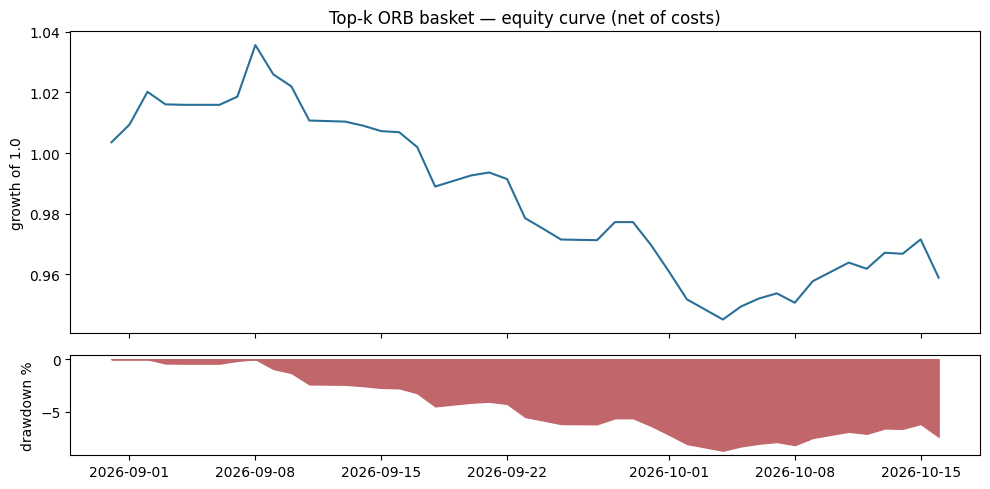

In [10]:
def simulate_orb_trade(session: Session, cfg: DayTradingConfig) -> Optional[dict]:
    """Simulate one long ORB breakout trade; returns None if the range never breaks."""
    bars, n_orb = session.bars, cfg.orb_minutes // cfg.bar_minutes
    opens, highs, lows, closes = (bars[col].to_numpy() for col in ["Open", "High", "Low", "Close"])
    orb_high = highs[:n_orb].max()

    breakouts = np.flatnonzero(highs[n_orb:] > orb_high)
    if breakouts.size == 0:
        return None
    entry_idx = n_orb + breakouts[0]
    entry = max(opens[entry_idx], orb_high)
    target, stop = entry * (1 + cfg.target_pct / 100), entry * (1 - cfg.stop_pct / 100)

    exit_idx, exit_price, reason = len(bars) - 1, closes[-1], "EOD"
    for i in range(entry_idx, len(bars)):
        if lows[i] <= stop:
            exit_idx, exit_price, reason = i, (min(stop, opens[i]) if i > entry_idx else stop), "STOP"
            break
        if highs[i] >= target:
            exit_idx, exit_price, reason = i, target, "TARGET"
            break

    gross_pct = (exit_price / entry - 1) * 100
    return {"entry_time": bars.index[entry_idx], "entry": entry, "exit_time": bars.index[exit_idx],
            "exit": exit_price, "reason": reason, "gross_pct": gross_pct,
            "net_pct": gross_pct - cfg.round_trip_cost_pct}


def run_backtest(baskets: pd.DataFrame, sessions: Dict[str, List[Session]], cfg: DayTradingConfig) -> pd.DataFrame:
    """Trade log for every selected (date, ticker)."""
    session_of = {(ticker, s.date): s for ticker, ticker_sessions in sessions.items() for s in ticker_sessions}
    trades = []
    for row in baskets[baskets["selected"]].itertuples():
        trade = simulate_orb_trade(session_of[(row.ticker, row.date)], cfg)
        if trade:
            trades.append({"date": row.date, "ticker": row.ticker, "market": row.market, "rank": row.rank, **trade})
    return pd.DataFrame(trades)


def performance_report(trades: pd.DataFrame, trading_days: pd.DatetimeIndex) -> Tuple[dict, pd.Series, pd.Series]:
    """Win rate, profit factor, Sharpe and max drawdown, plus the equity and drawdown curves."""
    daily = trades.groupby("date")["net_pct"].mean().reindex(trading_days, fill_value=0.0)
    equity = (1 + daily / 100).cumprod()
    drawdown = equity / equity.cummax() - 1
    wins, losses = trades.loc[trades["net_pct"] > 0, "net_pct"], trades.loc[trades["net_pct"] <= 0, "net_pct"]
    sharpe = daily.mean() / daily.std(ddof=1) * np.sqrt(252) if daily.std(ddof=1) > 0 else np.nan
    metrics = {
        "trades": len(trades),
        "win_rate_pct": 100 * len(wins) / len(trades),
        "profit_factor": wins.sum() / abs(losses.sum()) if losses.sum() != 0 else np.inf,
        "avg_trade_pct": trades["net_pct"].mean(),
        "sharpe_annualised": sharpe,
        "max_drawdown_pct": drawdown.min() * 100,
        "total_return_pct": (equity.iloc[-1] - 1) * 100,
    }
    return metrics, equity, drawdown


trading_days = pd.DatetimeIndex(sorted(baskets["date"].unique()))
trades = run_backtest(baskets, sessions, CFG)
metrics, equity, drawdown = performance_report(trades, trading_days)

print(f"Backtest window: {trading_days[0].date()} -> {trading_days[-1].date()}  ({len(trading_days)} sessions)")
print("Data sources:", sorted(set(data_sources.values())))
display(pd.Series(metrics, name="top-k basket").to_frame())
print("\nExit reasons:")
display(trades["reason"].value_counts().to_frame("trades"))
print("\nTrade log (last 10):")
display(trades.tail(10)[["date", "ticker", "rank", "entry", "exit", "reason", "net_pct"]])

# Does the ranking add anything? Compare against taking every name in the universe.
all_names_trades = run_backtest(build_baskets(features, replace(CFG, top_k=len(ALL_TICKERS))), sessions, CFG)
all_names_metrics, _, _ = performance_report(all_names_trades, trading_days)
display(pd.DataFrame({"top-k basket": metrics, "all names (no ranking)": all_names_metrics}))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.plot(equity.index, equity.values, color="#2a6f97")
ax1.set_title("Top-k ORB basket — equity curve (net of costs)")
ax1.set_ylabel("growth of 1.0")
ax2.fill_between(drawdown.index, drawdown.values * 100, color="#c1666b")
ax2.set_ylabel("drawdown %")
plt.tight_layout()
plt.show()

## 5. Long-term scorecard engine — 5 axes × 6 checks = 30 points (+ Altman Z / Z′)

Each axis is scored **0–6 by counting passed binary checks**, so every point is explainable. Thresholds are module-level
constants and parameters in the specification.

**Fundamentals source.** `download_fundamentals` reads annual statements from `yfinance`. Because Yahoo exposes no clean
multi-year consensus, forward growth is proxied by `forwardEps / trailingEps − 1` and `revenueGrowth`; a production system
would take consensus from a licensed provider (see spec §6). Fallback = **illustrative fixtures (approximate, rounded,
not real filings)** so the notebook runs offline. Monetary amounts are in millions of reporting currency.

In [11]:
@dataclass(frozen=True)
class MarketAssumptions:
    risk_free: float
    equity_risk_premium: float
    terminal_growth: float
    tax_rate: float
    credit_spread: float
    dividend_baseline: float   # yield considered "good" on this market


MARKET_ASSUMPTIONS = {
    "US": MarketAssumptions(0.042, 0.050, 0.025, 0.21, 0.015, dividend_baseline=0.02),
    "TASI": MarketAssumptions(0.050, 0.065, 0.030, 0.20, 0.015, dividend_baseline=0.05),
}
TARGET_YIELD = 0.05                      # Target-Yield fair value baseline (Saudi 5 % yield)
INDUSTRY_PE = {"NVDA": 35, "TSLA": 25, "AMD": 35, "AAPL": 28, "MSFT": 30, "2082.SR": 30, "7200.SR": 25, "2222.SR": 17}


def cagr(end: float, start: float, years: int) -> float:
    return (end / start) ** (1 / years) - 1 if start > 0 and end > 0 and years > 0 else np.nan


@dataclass(frozen=True)
class Fundamentals:
    ticker: str
    market: str
    price: float
    shares_m: float
    revenue: float
    revenue_start: float          # oldest year available (history_years ago)
    net_income: float
    net_income_start: float
    history_years: int
    ebit: float
    total_assets: float
    total_liabilities: float
    current_assets: float
    current_liabilities: float
    retained_earnings: float
    equity: float
    total_debt: float
    cash: float
    operating_cf: float
    capex: float
    dividend_per_share: float
    dps_history: Tuple[float, ...]    # completed years, oldest -> newest
    beta: float
    fwd_eps_growth: float
    fwd_revenue_growth: float
    industry_pe: float

    market_cap = property(lambda self: self.price * self.shares_m)
    eps = property(lambda self: self.net_income / self.shares_m)
    pe = property(lambda self: self.price / self.eps if self.eps > 0 else np.nan)
    pb = property(lambda self: self.market_cap / self.equity if self.equity > 0 else np.nan)
    roe = property(lambda self: self.net_income / self.equity if self.equity > 0 else np.nan)
    roce = property(lambda self: self.ebit / (self.total_assets - self.current_liabilities))
    fcf = property(lambda self: self.operating_cf - self.capex)
    dividend_yield = property(lambda self: self.dividend_per_share / self.price)
    payout_ratio = property(lambda self: self.dividend_per_share / self.eps if self.eps > 0 else np.nan)
    revenue_cagr = property(lambda self: cagr(self.revenue, self.revenue_start, self.history_years))
    net_income_cagr = property(lambda self: cagr(self.net_income, self.net_income_start, self.history_years))
    peg = property(lambda self: self.pe / (self.fwd_eps_growth * 100) if self.fwd_eps_growth > 0 else np.nan)


# Illustrative fixtures: rounded, approximate, for offline demos only — NOT sourced from filings.
_FIXTURE_ROWS = {
    # ticker: price, shares, rev, rev0, NI, NI0, EBIT, assets, liab, cur.assets, cur.liab, ret.earn, equity, debt, cash, ocf, capex, dps, dps history, beta, fwdEPS, fwdRev
    "AAPL":    (230, 15000, 391000, 366000, 94000, 94700, 123000, 365000, 308000, 153000, 176000, -19000, 57000, 106000, 30000, 118000, 9400, 1.00, (0.85, 0.87, 0.90, 0.94, 0.98), 1.2, 0.09, 0.06),
    "MSFT":    (420, 7430, 245000, 168000, 88000, 61000, 109000, 512000, 243000, 160000, 105000, 173000, 269000, 67000, 18000, 119000, 44000, 3.00, (2.0, 2.3, 2.5, 2.8, 3.0), 0.9, 0.13, 0.13),
    "NVDA":    (120, 24500, 130000, 27000, 73000, 9750, 81500, 111000, 32000, 80000, 18000, 68000, 79000, 8500, 8600, 64000, 3200, 0.01, (0.016, 0.016, 0.016, 0.016, 0.010), 1.7, 0.35, 0.40),
    "TSLA":    (250, 3200, 97000, 54000, 7100, 5500, 7100, 122000, 49000, 58000, 29000, 35000, 73000, 13000, 16000, 14900, 11300, 0.0, (0.0, 0.0, 0.0, 0.0, 0.0), 2.3, 0.15, 0.10),
    "AMD":     (150, 1620, 25800, 16400, 1600, 3160, 1900, 69000, 11000, 19000, 7300, 1100, 57000, 2500, 3900, 3000, 600, 0.0, (0.0, 0.0, 0.0, 0.0, 0.0), 1.8, 0.30, 0.20),
    "2222.SR": (27.5, 242000, 1780000, 1100000, 454000, 183000, 700000, 1970000, 820000, 700000, 450000, 800000, 1150000, 200000, 400000, 600000, 150000, 1.60, (0.7, 1.0, 1.2, 1.5, 1.6), 0.6, 0.04, 0.03),
    "2082.SR": (450, 733, 5000, 3600, 1000, 800, 1700, 60000, 45000, 8000, 6000, 3000, 15000, 30000, 4000, 1800, 5000, 3.0, (0.0, 0.0, 1.0, 2.0, 3.0), 0.8, 0.22, 0.18),
    "7200.SR": (150, 60, 3000, 1500, 300, 180, 380, 2500, 1500, 1800, 1100, 600, 1000, 300, 250, 330, 40, 6.0, (3.0, 4.0, 5.0, 5.5, 6.0), 0.7, 0.12, 0.15),
}


def fixture_fundamentals(ticker: str) -> Fundamentals:
    (price, shares, rev, rev0, ni, ni0, ebit, assets, liab, c_assets, c_liab, retained, equity, debt, cash,
     ocf, capex, dps, dps_hist, beta, g_eps, g_rev) = _FIXTURE_ROWS[ticker]
    return Fundamentals(ticker, market_of(ticker).name, price, shares, rev, rev0, ni, ni0, 3, ebit, assets, liab,
                        c_assets, c_liab, retained, equity, debt, cash, ocf, capex, dps, dps_hist, beta, g_eps, g_rev,
                        INDUSTRY_PE[ticker])


def _statement_value(statement: pd.DataFrame, labels: List[str], column: int = 0) -> float:
    for label in labels:
        if label in statement.index and pd.notna(statement.loc[label].iloc[column]):
            return float(statement.loc[label].iloc[column]) / 1e6
    raise KeyError(labels[0])


def download_fundamentals(ticker: str) -> Fundamentals:
    """Build Fundamentals from Yahoo annual statements (newest column = 0, oldest = last)."""
    stock = yf.Ticker(ticker)
    income, balance, cashflow, info = stock.financials, stock.balance_sheet, stock.cashflow, stock.info
    has_data = income.loc[["Total Revenue", "Net Income"]].notna().all().to_numpy()   # Yahoo pads the oldest year with NaN
    oldest = int(np.flatnonzero(has_data)[-1])
    if oldest < 2:
        raise ValueError("fewer than 3 annual statements available")

    dividends = stock.dividends
    annual = dividends.groupby(dividends.index.year).sum()
    completed = annual[annual.index < datetime.now().year].tail(5)
    trailing_eps, forward_eps = info.get("trailingEps"), info.get("forwardEps")
    fwd_eps_growth = forward_eps / trailing_eps - 1 if trailing_eps and forward_eps and trailing_eps > 0 else 0.0
    return Fundamentals(
        ticker, market_of(ticker).name,
        price=float(info.get("currentPrice") or info["regularMarketPrice"]),
        shares_m=info["sharesOutstanding"] / 1e6,
        revenue=_statement_value(income, ["Total Revenue"]),
        revenue_start=_statement_value(income, ["Total Revenue"], oldest),
        net_income=_statement_value(income, ["Net Income"]),
        net_income_start=_statement_value(income, ["Net Income"], oldest),
        history_years=oldest,
        ebit=_statement_value(income, ["EBIT", "Operating Income"]),
        total_assets=_statement_value(balance, ["Total Assets"]),
        total_liabilities=_statement_value(balance, ["Total Liabilities Net Minority Interest"]),
        current_assets=_statement_value(balance, ["Current Assets"]),
        current_liabilities=_statement_value(balance, ["Current Liabilities"]),
        retained_earnings=_statement_value(balance, ["Retained Earnings"]),
        equity=_statement_value(balance, ["Stockholders Equity", "Common Stock Equity"]),
        total_debt=_statement_value(balance, ["Total Debt"]),
        cash=_statement_value(balance, ["Cash And Cash Equivalents"]),
        operating_cf=_statement_value(cashflow, ["Operating Cash Flow"]),
        capex=abs(_statement_value(cashflow, ["Capital Expenditure"])),
        dividend_per_share=float(info.get("trailingAnnualDividendRate") or 0.0),
        dps_history=tuple(float(x) for x in completed),
        beta=float(info.get("beta") or 1.0),
        fwd_eps_growth=float(fwd_eps_growth),
        fwd_revenue_growth=float(info.get("revenueGrowth") or 0.0),
        industry_pe=INDUSTRY_PE[ticker],
    )


def load_fundamentals(tickers: List[str]) -> Tuple[Dict[str, Fundamentals], Dict[str, str]]:
    companies, sources = {}, {}
    for ticker in tickers:
        try:
            if yf is None or FORCE_FALLBACK_DATA:
                raise ImportError("yfinance unavailable or fallback forced")
            companies[ticker], sources[ticker] = download_fundamentals(ticker), "yfinance (real)"
        except Exception as exc:
            companies[ticker], sources[ticker] = fixture_fundamentals(ticker), f"ILLUSTRATIVE FIXTURE ({type(exc).__name__})"
    return companies, sources


companies, fundamentals_sources = load_fundamentals(ALL_TICKERS)
display(pd.DataFrame({
    "source": pd.Series(fundamentals_sources),
    "price": {t: c.price for t, c in companies.items()},
    "P/E": {t: c.pe for t, c in companies.items()},
    "P/B": {t: c.pb for t, c in companies.items()},
    "ROE": {t: c.roe for t, c in companies.items()},
    "div yield": {t: c.dividend_yield for t, c in companies.items()},
}))

,source,price,P/E,P/B,ROE,div yield
NVDA,yfinance (real),214.130,43.064,32.872,0.763,0.001
TSLA,yfinance (real),354.720,369.263,17.057,0.046,0.000
AMD,yfinance (real),528.750,199.117,13.701,0.069,0.000
AAPL,yfinance (real),343.460,44.751,67.982,1.519,0.003
MSFT,yfinance (real),529.050,29.372,8.880,0.302,0.007
2082.SR,yfinance (real),158.000,65.350,4.170,0.064,0.003
7200.SR,yfinance (real),298.000,93.038,25.856,0.278,0.005
2222.SR,yfinance (real),25.760,17.905,4.177,0.233,0.052


In [13]:
# --- Altman Z-score family ------------------------------------------------------------------------------
def altman_scores(f: Fundamentals) -> Dict[str, float]:
    """Original Z (public manufacturers, market equity) and Z' (private-firm variant, book equity).

    X1 = working capital / assets, X2 = retained earnings / assets, X3 = EBIT / assets,
    X4 = equity / total liabilities, X5 = sales / assets. Not meaningful for banks and insurers.
    """
    x1 = (f.current_assets - f.current_liabilities) / f.total_assets
    x2 = f.retained_earnings / f.total_assets
    x3 = f.ebit / f.total_assets
    x5 = f.revenue / f.total_assets
    z = 1.2 * x1 + 1.4 * x2 + 3.3 * x3 + 0.6 * (f.market_cap / f.total_liabilities) + 1.0 * x5
    z_prime = 0.717 * x1 + 0.847 * x2 + 3.107 * x3 + 0.420 * (f.equity / f.total_liabilities) + 0.998 * x5
    return {"z": z, "z_prime": z_prime}


def altman_zone(score: float, distress_below: float, safe_above: float) -> str:
    return "distress" if score < distress_below else "safe" if score > safe_above else "grey"


# --- The five axes: each returns the checks it evaluated (name -> passed) -----------------------------------
def value_checks(f: Fundamentals, dcf_value: Optional[float]) -> Dict[str, bool]:
    return {
        "P/E below industry P/E": 0 < f.pe < f.industry_pe,
        "P/B below 3": 0 < f.pb < 3,
        "Price below DCF value": dcf_value is not None and f.price < dcf_value,
        "20% margin of safety vs DCF": dcf_value is not None and f.price <= 0.8 * dcf_value,
        "FCF yield above 4%": f.fcf / f.market_cap > 0.04,
        "P/E below 25": 0 < f.pe < 25,
    }


def dividend_checks(f: Fundamentals) -> Dict[str, bool]:
    history = f.dps_history
    return {
        "Pays a dividend": f.dividend_per_share > 0,
        "Yield at or above market baseline": f.dividend_yield >= MARKET_ASSUMPTIONS[f.market].dividend_baseline,
        "Payout ratio between 0 and 75%": 0 < f.payout_ratio <= 0.75,
        "Dividend covered by free cash flow": f.dividend_per_share * f.shares_m <= f.fcf,
        "Dividend per share grew over history": len(history) >= 2 and history[0] > 0 and history[-1] > history[0],
        "No dividend cut in history": len(history) >= 3 and all(b >= a for a, b in zip(history, history[1:])) and history[0] > 0,
    }


def health_checks(f: Fundamentals) -> Dict[str, bool]:
    z = altman_scores(f)["z"]
    return {
        "Debt/Equity below 1": f.equity > 0 and f.total_debt / f.equity < 1,
        "Current ratio above 1.5": f.current_assets / f.current_liabilities > 1.5,
        "Cash covers 25% of debt": f.total_debt == 0 or f.cash / f.total_debt >= 0.25,
        "Operating cash flow covers 20% of debt": f.total_debt == 0 or f.operating_cf / f.total_debt >= 0.20,
        "Altman Z above 1.81 (not distressed)": z > 1.81,
        "Altman Z above 2.99 (safe zone)": z > 2.99,
    }


def past_performance_checks(f: Fundamentals) -> Dict[str, bool]:
    return {
        "Revenue CAGR above 5%": f.revenue_cagr > 0.05,
        "Revenue CAGR above 10%": f.revenue_cagr > 0.10,
        "Net income CAGR above 5%": f.net_income_cagr > 0.05,
        "Net income CAGR above 10%": f.net_income_cagr > 0.10,
        "ROE above 15%": f.roe > 0.15,
        "ROCE above 12%": f.roce > 0.12,
    }


def future_growth_checks(f: Fundamentals) -> Dict[str, bool]:
    return {
        "Forward EPS growth above 5%": f.fwd_eps_growth > 0.05,
        "Forward EPS growth above 10%": f.fwd_eps_growth > 0.10,
        "Forward revenue growth above 5%": f.fwd_revenue_growth > 0.05,
        "Forward revenue growth above 10%": f.fwd_revenue_growth > 0.10,
        "PEG below 2": 0 < f.peg < 2,
        "PEG below 1": 0 < f.peg < 1,
    }


AXES = ["Value", "Dividend", "Health", "Past", "Future"]


def score_company(f: Fundamentals, dcf_value: Optional[float]) -> dict:
    """Run all 30 checks. Returns per-axis scores (0-6), the total (0-30) and the passed-check names."""
    results = {
        "Value": value_checks(f, dcf_value), "Dividend": dividend_checks(f), "Health": health_checks(f),
        "Past": past_performance_checks(f), "Future": future_growth_checks(f),
    }
    axis_scores = {axis: int(sum(bool(v) for v in checks.values())) for axis, checks in results.items()}
    return {"axes": axis_scores, "total": sum(axis_scores.values()),
            "passed": {axis: [name for name, ok in checks.items() if ok] for axis, checks in results.items()}}


altman_table = pd.DataFrame({
    t: {**altman_scores(f), "Z zone": altman_zone(altman_scores(f)["z"], 1.81, 2.99),
        "Z' zone": altman_zone(altman_scores(f)["z_prime"], 1.23, 2.90)}
    for t, f in companies.items()}).T
print("Altman Z (distress < 1.81 < grey < 2.99 < safe) and Z' (distress < 1.23 < grey < 2.90 < safe):")
display(altman_table)

Altman Z (distress < 1.81 < grey < 2.99 < safe) and Z' (distress < 1.23 < grey < 2.90 < safe):


,z,z_prime,Z zone,Z' zone
NVDA,67.504,5.431,safe,safe
TSLA,16.840,1.873,safe,grey
AMD,38.215,2.759,safe,grey
AAPL,12.800,2.346,safe,grey
MSFT,9.300,2.120,safe,grey
2082.SR,2.471,0.772,grey,distress
7200.SR,2.564,0.612,grey,distress
2222.SR,6.973,2.816,safe,grey


## 6. Valuation engine — Target-Yield fair value vs multi-stage FCFF DCF

$$\text{FV}_{\text{yield}} = \frac{\text{DPS}}{0.05} \qquad
\text{FV}_{\text{DCF}} = \frac{\sum_{t=1}^{10}\frac{FCFF_t}{(1+r)^t} + \frac{TV}{(1+r)^{10}} - D + C}{N}$$

* **FCFF₀** = operating cash flow − capex + after-tax interest, with interest estimated as `cost of debt × debt`
  (Yahoo gives no clean interest line).
* **Growth:** years 1–5 at `g₀` = forward EPS growth clipped to [terminal g, 15 %]; years 6–10 fade linearly to the terminal rate.
* **Discount rate:** WACC with CAPM cost of equity, floored at risk-free + 2 %. **Terminal value:** Gordon growth.
* **Margin of safety** = (FV − price) / FV. Bands: ≥ +20 % *Undervalued*, −20 % … +20 % *Fairly valued*, ≤ −20 % *Overvalued*.

The two values answer different questions: Target-Yield asks "is the *income* priced at a 5 % yield?"; DCF asks "is the
*business* worth more than its price?". A US growth stock will look overvalued on the first and may look fair on the second.

Valuation (fair values per share; MoS = margin of safety):


,price,wacc,target_yield_fv,target_yield_mos,target_yield_class,dcf_fv,dcf_mos,dcf_class
NVDA,214.130,0.153,5.600,-37.237,Overvalued,59.478,-2.600,Overvalued
TSLA,354.720,0.137,None,None,n/a,30.433,-10.656,Overvalued
AMD,528.750,0.164,None,None,n/a,57.593,-8.181,Overvalued
AAPL,343.460,0.094,21.000,-15.355,Overvalued,152.605,-1.251,Overvalued
MSFT,529.050,0.096,72.800,-6.267,Overvalued,263.053,-1.011,Overvalued
2082.SR,158.000,0.070,9.200,-16.174,Overvalued,87.068,-0.815,Overvalued
7200.SR,298.000,0.073,32.000,-8.312,Overvalued,430.881,0.308,Undervalued
2222.SR,25.760,0.070,26.980,0.045,Fairly valued,35.615,0.277,Undervalued



5-axis scorecard (each axis 0-6):


,Value,Dividend,Health,Past,Future,TOTAL /30
NVDA,0,5,6,6,6,23
TSLA,0,1,6,1,4,12
AMD,0,1,6,4,6,17
AAPL,0,5,4,2,3,14
MSFT,1,5,5,6,6,23
2082.SR,0,2,3,3,6,14
7200.SR,2,5,3,4,4,18
2222.SR,4,3,6,2,2,17


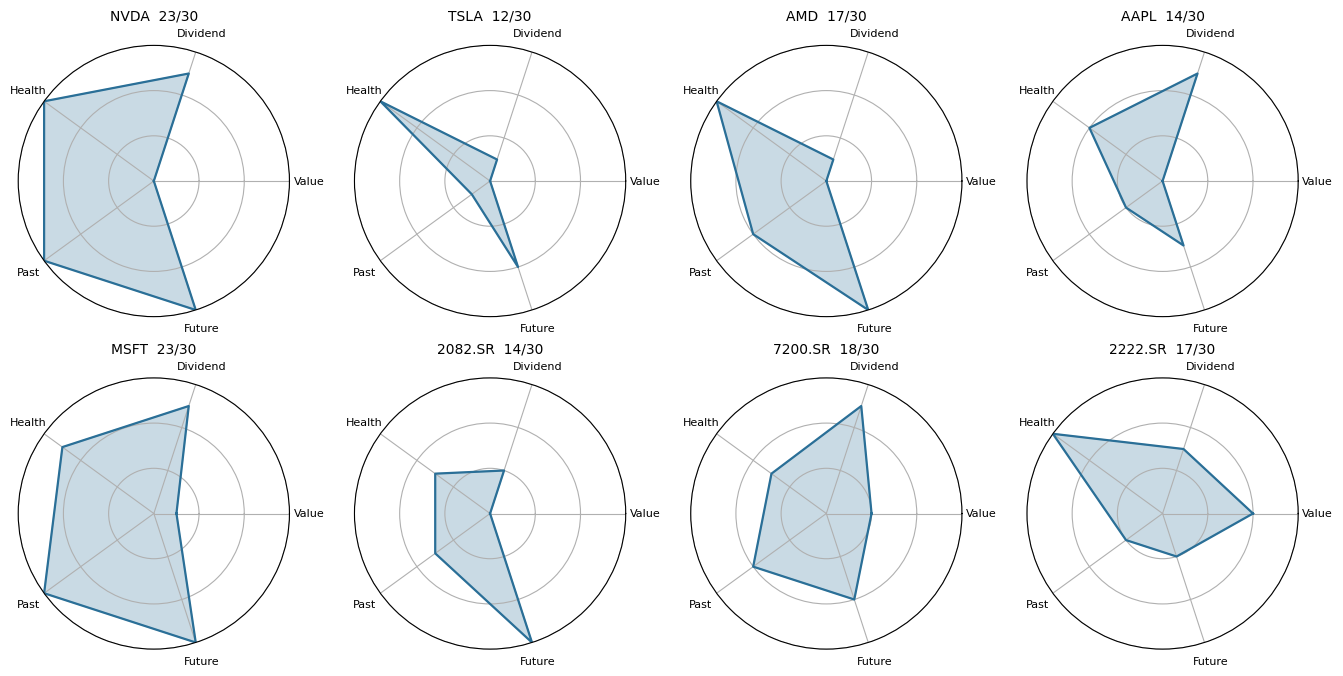

In [14]:
STAGE_YEARS, FADE_YEARS, MAX_GROWTH = 5, 5, 0.15
MIN_WACC_PREMIUM = 0.02                  # WACC floor = risk-free + 2 %
MOS_BAND = 0.20


def target_yield_fair_value(dividend_per_share: float, target_yield: float = TARGET_YIELD) -> Optional[float]:
    return dividend_per_share / target_yield if dividend_per_share > 0 else None


def cost_of_debt(a: MarketAssumptions) -> float:
    return a.risk_free + a.credit_spread


def wacc(f: Fundamentals, a: MarketAssumptions) -> float:
    cost_of_equity = a.risk_free + f.beta * a.equity_risk_premium
    equity_value, debt_value = f.market_cap, f.total_debt
    blended = ((equity_value * cost_of_equity + debt_value * cost_of_debt(a) * (1 - a.tax_rate))
               / (equity_value + debt_value))
    return max(blended, a.risk_free + MIN_WACC_PREMIUM)   # low-beta, high-debt names must not discount below risk-free


def dcf_fair_value(f: Fundamentals, a: MarketAssumptions) -> Optional[float]:
    """Per-share value from a 5 + 5 year fading-growth FCFF model; None when base FCFF is not positive."""
    fcff0 = f.operating_cf - f.capex + cost_of_debt(a) * f.total_debt * (1 - a.tax_rate)
    rate = wacc(f, a)
    if fcff0 <= 0 or rate <= a.terminal_growth + 0.01:
        return None
    g0 = min(max(f.fwd_eps_growth, a.terminal_growth), MAX_GROWTH)
    fade = np.linspace(g0, a.terminal_growth, FADE_YEARS + 1)[1:]
    growth = np.r_[np.full(STAGE_YEARS, g0), fade]
    fcff = fcff0 * np.cumprod(1 + growth)
    discount = (1 + rate) ** np.arange(1, len(fcff) + 1)
    terminal_value = fcff[-1] * (1 + a.terminal_growth) / (rate - a.terminal_growth)
    enterprise_value = (fcff / discount).sum() + terminal_value / discount[-1]
    return (enterprise_value - f.total_debt + f.cash) / f.shares_m


def margin_of_safety(fair_value: Optional[float], price: float) -> Optional[float]:
    return (fair_value - price) / fair_value if fair_value else None


def classify(mos: Optional[float]) -> str:
    if mos is None:
        return "n/a"
    return "Undervalued" if mos >= MOS_BAND else "Overvalued" if mos <= -MOS_BAND else "Fairly valued"


def value_company(f: Fundamentals) -> dict:
    a = MARKET_ASSUMPTIONS[f.market]
    fv_yield, fv_dcf = target_yield_fair_value(f.dividend_per_share), dcf_fair_value(f, a)
    mos_yield, mos_dcf = margin_of_safety(fv_yield, f.price), margin_of_safety(fv_dcf, f.price)
    return {"price": f.price, "wacc": wacc(f, a),
            "target_yield_fv": fv_yield, "target_yield_mos": mos_yield, "target_yield_class": classify(mos_yield),
            "dcf_fv": fv_dcf, "dcf_mos": mos_dcf, "dcf_class": classify(mos_dcf)}


valuations = {t: value_company(f) for t, f in companies.items()}
scorecards = {t: score_company(f, valuations[t]["dcf_fv"]) for t, f in companies.items()}

print("Valuation (fair values per share; MoS = margin of safety):")
display(pd.DataFrame(valuations).T)

scorecard_table = pd.DataFrame({t: {**s["axes"], "TOTAL /30": s["total"]} for t, s in scorecards.items()}).T
print("\n5-axis scorecard (each axis 0-6):")
display(scorecard_table)


def plot_radars(scorecards: Dict[str, dict]) -> None:
    angles = np.linspace(0, 2 * np.pi, len(AXES), endpoint=False).tolist()
    cols = 4
    rows = int(np.ceil(len(scorecards) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.4 * rows), subplot_kw={"polar": True}, squeeze=False)
    for ax in axes.flat:
        ax.set_visible(False)
    for ax, (ticker, card) in zip(axes.flat, scorecards.items()):
        values = [card["axes"][axis] for axis in AXES]
        ax.set_visible(True)
        ax.plot(angles + angles[:1], values + values[:1], color="#2a6f97", lw=1.6)
        ax.fill(angles + angles[:1], values + values[:1], color="#2a6f97", alpha=0.25)
        ax.set_xticks(angles)
        ax.set_xticklabels(AXES, fontsize=8)
        ax.set_ylim(0, 6)
        ax.set_yticks([2, 4, 6])
        ax.set_yticklabels([])
        ax.set_title(f"{ticker}  {card['total']}/30", fontsize=10)
    plt.tight_layout()
    plt.show()


plot_radars(scorecards)

## 7. Financial NLP — lexical sentiment and risk flags on disclosure text

Method: **Loughran–McDonald (LM)** style word counting, the standard for financial text (general-purpose lexicons mislabel
words like *liability* or *tax*). The word lists below are a **small illustrative subset** — in production, load the full LM
master dictionary. LM convention: a positive word preceded by a negator within 3 tokens counts as negative.

`finbert_net_sentiment` is an optional transformer scorer (needs `pip install transformers torch`); it is not run by default.

The sample passages are **illustrative paraphrases**, not quotations from real filings.

In [15]:
LM_POSITIVE = {"strong", "growth", "improved", "improvement", "record", "increase", "increased", "gain", "gains",
               "profitable", "efficient", "successful", "opportunity", "outperformed", "robust", "achieved", "exceeded"}
LM_NEGATIVE = {"loss", "losses", "decline", "declined", "adverse", "impairment", "weak", "weakness", "decrease",
               "decreased", "difficult", "deterioration", "default", "litigation", "shortfall", "downturn",
               "unfavorable", "failure", "negative", "severe", "restructuring", "disruption", "delay", "delays"}
LM_UNCERTAINTY = {"may", "might", "uncertain", "uncertainty", "uncertainties", "unpredictable", "volatile",
                  "volatility", "approximately", "depend", "depends", "could", "possible", "risk", "risks"}
LM_LITIGIOUS = {"lawsuit", "lawsuits", "litigation", "plaintiff", "regulatory", "investigation", "penalty",
                "penalties", "violation", "claims", "arbitration", "subpoena"}
NEGATORS = {"no", "not", "never", "none", "neither", "nor", "cannot", "without"}

SAMPLE_DISCLOSURES = {
    "AAPL": "Net sales increased driven by record services revenue and strong demand. Gross margin improved and we "
            "achieved robust operating cash flow. Foreign currency volatility and regulatory investigation outcomes "
            "could adversely affect results, and supply chain delays may occur.",
    "TSLA": "Results were negatively affected by lower average selling prices. Production delays and weak demand in "
            "certain regions produced a decline in margins. Pending litigation and regulatory claims remain uncertain "
            "and we cannot predict their outcome. We did not achieve our delivery goals.",
    "2222.SR": "The Board notes strong earnings and a record dividend distribution supported by a robust balance sheet. "
               "Crude oil price volatility may affect future results, but the Company exceeded its operational targets "
               "and increased its investment in capacity expansion.",
}


def tokenize(text: str) -> List[str]:
    return re.findall(r"[a-z][a-z'\-]*", text.lower())


def lm_sentiment(text: str) -> dict:
    """LM word-count sentiment with negation handling plus uncertainty and litigation densities (per 1,000 words)."""
    tokens = tokenize(text)
    positive = negative = 0
    for i, token in enumerate(tokens):
        negated = any(prev in NEGATORS for prev in tokens[max(0, i - 3):i])
        if token in LM_POSITIVE:
            positive, negative = (positive, negative + 1) if negated else (positive + 1, negative)
        elif token in LM_NEGATIVE:
            negative += 1
    per_thousand = 1000 / max(len(tokens), 1)
    net = (positive - negative) / max(positive + negative, 1)
    return {
        "words": len(tokens), "positive": positive, "negative": negative, "net_sentiment": net,
        "label": "positive" if net > 0.2 else "negative" if net < -0.2 else "neutral",
        "uncertainty_per_1k": sum(t in LM_UNCERTAINTY for t in tokens) * per_thousand,
        "litigious_per_1k": sum(t in LM_LITIGIOUS for t in tokens) * per_thousand,
        "risk_terms": sorted({t for t in tokens if t in LM_UNCERTAINTY | LM_LITIGIOUS | LM_NEGATIVE}),
    }


def finbert_net_sentiment(text: str) -> float:  # optional, not executed by default
    """P(positive) - P(negative) from ProsusAI/finbert, averaged over 512-token chunks."""
    from transformers import pipeline
    classifier = pipeline("text-classification", model="ProsusAI/finbert", top_k=None, truncation=True, max_length=512)
    scores = {item["label"].lower(): item["score"] for item in classifier(text)[0]}
    return scores.get("positive", 0.0) - scores.get("negative", 0.0)


sentiments = {ticker: lm_sentiment(text) for ticker, text in SAMPLE_DISCLOSURES.items()}
display(pd.DataFrame(sentiments).T.drop(columns="risk_terms"))
for ticker, result in sentiments.items():
    print(f"{ticker:8s} risk terms: {', '.join(result['risk_terms'])}")

,words,positive,negative,net_sentiment,label,uncertainty_per_1k,litigious_per_1k
AAPL,38,6,1,0.714,positive,78.947,52.632
TSLA,42,0,4,-1.000,negative,23.810,71.429
2222.SR,38,5,0,1.000,positive,52.632,0.000


AAPL     risk terms: could, delays, investigation, may, regulatory, volatility
TSLA     risk terms: claims, decline, delays, litigation, regulatory, uncertain, weak
2222.SR  risk terms: may, volatility


## 8. Summary and output verification

Assembles the JSON payload the stoX API would serve and prints presentation tables. Every numeric field is a descriptive
statistic; the payload carries the compliance disclaimer.

In [16]:
def to_native(value):
    """Make numpy / pandas values JSON-safe (NaN and ±inf become null)."""
    if isinstance(value, dict):
        return {str(k): to_native(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_native(v) for v in value]
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.strftime("%Y-%m-%d")
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, (np.integer, int)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return round(float(value), 4) if np.isfinite(value) else None
    return value


FACTOR_COLUMNS = ["rvol", "atr_pct", "gap_pct", "vwap_dev_pct", "roc_pct", "accel_pct", "spread_pct",
                  "overnight_vol_ratio", "overnight_break"]

payload = {
    "generated_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "disclaimer": "Descriptive quantitative analytics only. Not investment advice or a recommendation to buy or sell.",
    "data_sources": {"intraday": data_sources, "fundamentals": fundamentals_sources},
    "day_trading": {
        "config": {"orb_minutes": CFG.orb_minutes, "target_pct": CFG.target_pct, "stop_pct": CFG.stop_pct,
                   "top_k": CFG.top_k, "weights": CFG.weights},
        "baskets": {
            market_name: {
                "date": rows["date"].iloc[0],
                "candidates": [{"rank": r.rank, "ticker": r.ticker, "composite_score": r.score,
                                "selected": r.selected, "relaxed_filters": r.relaxed,
                                "factors": {c: getattr(r, c) for c in FACTOR_COLUMNS}} for r in rows.itertuples()],
            } for market_name, rows in latest_basket.items()},
        "backtest": metrics,
    },
    "long_term": {
        ticker: {
            "market": f.market,
            "scorecard": scorecards[ticker],
            "altman": altman_scores(f),
            "valuation": valuations[ticker],
            "filing_sentiment": {k: v for k, v in sentiments.get(ticker, {}).items() if k != "risk_terms"} or None,
        } for ticker, f in companies.items()},
}
payload = to_native(payload)
json.dumps(payload)  # raises if anything is not serialisable

print("=== JSON payload (long-term entry for AAPL) ===")
print(json.dumps(payload["long_term"]["AAPL"], indent=2))
print("\n=== JSON payload (day-trading basket) ===")
print(json.dumps(payload["day_trading"]["baskets"], indent=2)[:2500], "...")

=== JSON payload (long-term entry for AAPL) ===
{
  "market": "US",
  "scorecard": {
    "axes": {
      "Value": 0,
      "Dividend": 5,
      "Health": 4,
      "Past": 2,
      "Future": 3
    },
    "total": 14,
    "passed": {
      "Value": [],
      "Dividend": [
        "Pays a dividend",
        "Payout ratio between 0 and 75%",
        "Dividend covered by free cash flow",
        "Dividend per share grew over history",
        "No dividend cut in history"
      ],
      "Health": [
        "Cash covers 25% of debt",
        "Operating cash flow covers 20% of debt",
        "Altman Z above 1.81 (not distressed)",
        "Altman Z above 2.99 (safe zone)"
      ],
      "Past": [
        "ROE above 15%",
        "ROCE above 12%"
      ],
      "Future": [
        "Forward EPS growth above 5%",
        "Forward revenue growth above 5%",
        "Forward revenue growth above 10%"
      ]
    }
  },
  "altman": {
    "z": 12.7999,
    "z_prime": 2.3464
  },
  "valuation": {
    "

In [17]:
summary = pd.DataFrame({
    "scorecard /30": {t: s["total"] for t, s in scorecards.items()},
    "yield FV": {t: v["target_yield_fv"] for t, v in valuations.items()},
    "yield class": {t: v["target_yield_class"] for t, v in valuations.items()},
    "DCF FV": {t: v["dcf_fv"] for t, v in valuations.items()},
    "DCF class": {t: v["dcf_class"] for t, v in valuations.items()},
    "Altman Z": {t: altman_scores(f)["z"] for t, f in companies.items()},
})
summary.insert(0, "price", {t: v["price"] for t, v in valuations.items()})
print("Long-term summary (descriptive analytics; fundamentals source: "
      f"{sorted(set(fundamentals_sources.values()))})")
display(summary)
print("\nDay-trading backtest summary (data:", sorted(set(data_sources.values())), ")")
display(pd.Series(metrics).to_frame("value"))

# Self-checks: cheap invariants that fail loudly if a change breaks the engine.
assert all(0 <= v <= 6 for card in scorecards.values() for v in card["axes"].values())
assert all(card["total"] == sum(card["axes"].values()) for card in scorecards.values())
assert all(3 <= rows["selected"].sum() <= 5 or len(rows) < 3 for _, rows in baskets.groupby(["date", "market"]))
assert target_yield_fair_value(1.50) == 30.0
print("\nAll self-checks passed.")

Long-term summary (descriptive analytics; fundamentals source: ['yfinance (real)'])


,price,scorecard /30,yield FV,yield class,DCF FV,DCF class,Altman Z
NVDA,214.130,23,5.600,Overvalued,59.478,Overvalued,67.504
TSLA,354.720,12,NaN,n/a,30.433,Overvalued,16.840
AMD,528.750,17,NaN,n/a,57.593,Overvalued,38.215
AAPL,343.460,14,21.000,Overvalued,152.605,Overvalued,12.800
MSFT,529.050,23,72.800,Overvalued,263.053,Overvalued,9.300
2082.SR,158.000,14,9.200,Overvalued,87.068,Overvalued,2.471
7200.SR,298.000,18,32.000,Overvalued,430.881,Undervalued,2.564
2222.SR,25.760,17,26.980,Fairly valued,35.615,Undervalued,6.973



Day-trading backtest summary (data: ['yfinance (real)'] )


,value
trades,105.000
win_rate_pct,37.143
profit_factor,0.831
avg_trade_pct,-0.080
sharpe_annualised,-2.408
max_drawdown_pct,-8.745
total_return_pct,-4.111



All self-checks passed.


# Part 2 - AI ranking, daily tracking and the quarterly report
Built from the supervisor's review comments.

| What the supervisor asked for | Where it is implemented | How to read it |
|---|---|---|
| "How did the AI choose this stock?" | Sections 10 and 11 | A machine-learning model learns the weights from history; every pick gets a plain-English reason |
| Analysis over several timeframes (5 days, 10 days, a month, a year) | Section 9 | Return and volatility factors over 5, 10, 21 and 252 days feed the model |
| Daily picks, then "did it succeed or not" | Section 13 | Each pick is stored before the open and its result after the close |
| The model's success rate after a month | Section 13 | A ready monthly table (`v_monthly_success`) |
| A report refreshed every quarter | Section 14 | All stocks ranked by the 30-point scorecard |
| Making sure the results are not an illusion | Sections 9, 10 and 12 | No look-ahead leakage, plus a test that plants a real pattern to see whether the model finds it |

**Strict rule:** everything shown here is a descriptive statistic about the picks, not a recommendation to buy or sell.
If the data source is `SYNTHETIC`, the numbers say nothing about real markets; they only prove the machinery works.
Run the notebook on your own machine with internet access so it uses real `yfinance` data (five years of daily bars per stock).

## 9. Daily data and multi-timeframe features

**In plain words:** training a model needs years of history, while 5-minute bars are only available for about two months,
so we use daily bars. For each stock, every morning before the open, we compute how much it rose over the last week, two weeks,
month and year, how much it fluctuates, how busy trading was yesterday, and whether it opened with a gap. Then we ask:
**will it close at least 2 % above its open today?**

**Technical:** every feature at session *t* uses only the open of *t* and data up to *t-1*; `assert_no_lookahead` proves it by
recomputing features on truncated history. Universe >= 20 names per market (spec section 3.5). If any real series loads, the
experiment never mixes in synthetic ones.

In [ ]:
ML_UNIVERSE_US = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL", "META", "TSLA", "AMD", "NFLX", "AVGO", "INTC", "CRM",
                  "ORCL", "ADBE", "QCOM", "MU", "PYPL", "UBER", "COIN", "PLTR", "SHOP", "BA", "DIS", "JPM", "XOM"]
ML_UNIVERSE_TASI = ["2222.SR", "1120.SR", "2010.SR", "7010.SR", "1180.SR", "2082.SR", "7200.SR", "1211.SR", "2280.SR",
                    "1150.SR", "1010.SR", "1060.SR", "1050.SR", "5110.SR", "2020.SR", "2350.SR", "4190.SR", "4001.SR",
                    "2310.SR", "2290.SR"]
ML_UNIVERSE = ML_UNIVERSE_US + ML_UNIVERSE_TASI     # >= 20 liquid names per market, as the spec recommends (section 3.5)

DISPLAY_NAMES = {   # English display names (used by reports only; Yahoo symbols stay the keys)
    "AAPL": "Apple",
    "MSFT": "Microsoft",
    "NVDA": "NVIDIA",
    "AMZN": "Amazon",
    "GOOGL": "Alphabet (Google)",
    "META": "Meta",
    "TSLA": "Tesla",
    "AMD": "AMD",
    "NFLX": "Netflix",
    "AVGO": "Broadcom",
    "INTC": "Intel",
    "CRM": "Salesforce",
    "ORCL": "Oracle",
    "ADBE": "Adobe",
    "QCOM": "Qualcomm",
    "MU": "Micron",
    "PYPL": "PayPal",
    "UBER": "Uber",
    "COIN": "Coinbase",
    "PLTR": "Palantir",
    "SHOP": "Shopify",
    "BA": "Boeing",
    "DIS": "Disney",
    "JPM": "JPMorgan Chase",
    "XOM": "Exxon Mobil",
    "2222.SR": "Saudi Aramco",
    "1120.SR": "Al Rajhi Bank",
    "2010.SR": "SABIC",
    "7010.SR": "stc",
    "1180.SR": "Saudi National Bank",
    "2082.SR": "ACWA Power",
    "7200.SR": "Almoammar Information Systems",
    "1211.SR": "Ma'aden",
    "2280.SR": "Almarai",
    "1150.SR": "Alinma Bank",
    "1010.SR": "Riyad Bank",
    "1060.SR": "Saudi Awwal Bank",
    "1050.SR": "Banque Saudi Fransi",
    "5110.SR": "Saudi Electricity",
    "2020.SR": "SABIC Agri-Nutrients",
    "2350.SR": "Saudi Kayan",
    "4190.SR": "Jarir",
    "4001.SR": "Othaim Markets",
    "2310.SR": "Sipchem",
    "2290.SR": "Yansab",
}


def download_daily(ticker: str, years: int = 5) -> pd.DataFrame:
    """Daily OHLCV, split/dividend-adjusted (adjusting every column keeps intraday ratios intact)."""
    raw = yf.download(ticker, period=f"{years}y", interval="1d", auto_adjust=True, progress=False)
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    bars = raw[OHLCV].dropna()
    bars = bars[bars["Volume"] > 0]
    if len(bars) < 600:
        raise ValueError(f"only {len(bars)} daily bars for {ticker}")
    index = pd.DatetimeIndex(bars.index)
    bars.index = (index.tz_localize(None) if index.tz is not None else index).normalize()
    return bars


def synthetic_daily(ticker: str, market: Market, days: int = 1000, planted_effect: float = 0.0) -> pd.DataFrame:
    """Deterministic stand-in for daily bars: a random walk with volatility clustering and path-consistent OHLC.

    It contains NO market information. `planted_effect` > 0 is used ONLY by the labelled positive-control experiment
    (section 11): on days that open > +1 % above the previous close the intraday drift is raised by that fraction.
    """
    rng = np.random.default_rng(zlib.crc32(ticker.encode()) + (7919 if planted_effect else 0))
    weekmask = "Sun Mon Tue Wed Thu" if market is TASI else "Mon Tue Wed Thu Fri"
    dates = pd.bdate_range(end=pd.Timestamp.today().normalize(), periods=days, freq="C", weekmask=weekmask)
    n, steps = len(dates), 78
    log_sigma = np.zeros(n)                                   # persistent volatility regime (volatility clusters)
    shocks = rng.normal(0, 0.15, n)
    for t in range(1, n):
        log_sigma[t] = 0.92 * log_sigma[t - 1] + shocks[t]
    sigma = rng.uniform(0.012, 0.030) * np.exp(log_sigma)     # daily volatility, differs per stock
    gap = sigma * 0.35 * rng.standard_t(4, n) / np.sqrt(2)
    drift = planted_effect * (gap > 0.01) / steps
    path = np.cumsum(rng.normal(0, 1, (n, steps)) * (sigma * 0.9 / np.sqrt(steps))[:, None] + drift[:, None], axis=1)
    close = rng.uniform(30, 300) * np.exp(np.cumsum(gap + path[:, -1]))
    open_ = np.r_[close[0] * np.exp(-(gap[0] + path[0, -1])), close[:-1]] * np.exp(gap)
    high = open_ * np.exp(np.maximum(path.max(axis=1), 0))
    low = open_ * np.exp(np.minimum(path.min(axis=1), 0))
    volume_ar = np.zeros(n)
    volume_shocks = rng.normal(0, 0.35, n)
    for t in range(1, n):
        volume_ar[t] = 0.8 * volume_ar[t - 1] + volume_shocks[t]
    volume = np.exp(rng.uniform(11, 16)) * np.exp(0.6 * log_sigma + 0.5 * volume_ar)
    return pd.DataFrame({"Open": open_, "High": high, "Low": low, "Close": close, "Volume": volume.round()}, index=dates)


def load_daily(tickers: List[str]) -> Tuple[Dict[str, pd.DataFrame], Dict[str, str]]:
    data, sources = {}, {}
    for ticker in tickers:
        try:
            if yf is None or FORCE_FALLBACK_DATA:
                raise ImportError("yfinance unavailable or fallback forced")
            data[ticker], sources[ticker] = download_daily(ticker), "yfinance (real)"
        except Exception as exc:
            data[ticker] = synthetic_daily(ticker, market_of(ticker))
            sources[ticker] = f"SYNTHETIC ({type(exc).__name__})"
    return data, sources


def training_universe(daily: Dict[str, pd.DataFrame], sources: Dict[str, str]) -> Dict[str, pd.DataFrame]:
    """Never train on a mix: if any real series exist, keep only the real ones; otherwise the whole run is synthetic."""
    real = {t: d for t, d in daily.items() if sources[t].startswith("yfinance")}
    return real if real else daily


daily_all, daily_sources = load_daily(ML_UNIVERSE)
daily_data = training_universe(daily_all, daily_sources)
DATA_MODE = "REAL" if all(daily_sources[t].startswith("yfinance") for t in daily_data) else "SYNTHETIC"
print(f"AI experiment data mode: {DATA_MODE} — {len(daily_data)} tickers "
      f"({sum(market_of(t) is US for t in daily_data)} US, {sum(market_of(t) is TASI for t in daily_data)} TASI), "
      f"{min(len(d) for d in daily_data.values())}-{max(len(d) for d in daily_data.values())} daily bars each")
if DATA_MODE == "SYNTHETIC":
    print("WARNING: synthetic data contains no market information — any 'result' below only proves the machinery works.")

In [ ]:
HORIZONS = (5, 10, 21, 252)    # trading days ≈ 1 week, 2 weeks, 1 month, 1 year (the "timeframes" asked for in review)
ML_FEATURES = ["gap_pct", "rvol", "atr_pct", "spread_pct", "ret_1d", "ret_5d", "ret_10d", "ret_21d", "ret_252d",
               "vol_21d", "dist_high_252d", "is_tasi"]


def daily_features(bars: pd.DataFrame, cfg: DayTradingConfig = CFG) -> pd.DataFrame:
    """Pre-open feature row for every session t. Only the OPEN of day t and data up to day t-1 are used (no look-ahead)."""
    o, h, l, c, v = (bars[col] for col in OHLCV)
    prev_close = c.shift(1)
    true_range = pd.concat([h - l, (h - prev_close).abs(), (l - prev_close).abs()], axis=1).max(axis=1)
    day_return = c.pct_change()
    out = pd.DataFrame(index=bars.index)
    out["gap_pct"] = (o / prev_close - 1) * 100                                   # known the moment the market opens
    out["rvol"] = v.shift(1) / v.shift(2).rolling(cfg.lookback_days).mean()       # prior session's relative volume
    out["atr_pct"] = true_range.rolling(cfg.atr_days).mean().shift(1) / prev_close * 100
    out["spread_pct"] = corwin_schultz_spread(h, l).rolling(cfg.lookback_days).mean().shift(1) * 100
    out["ret_1d"] = day_return.shift(1) * 100
    for n in HORIZONS:
        out[f"ret_{n}d"] = (c.shift(1) / c.shift(1 + n) - 1) * 100                # momentum over the last n sessions
    out["vol_21d"] = day_return.shift(1).rolling(21).std() * 100
    out["dist_high_252d"] = (c.shift(1) / h.shift(1).rolling(252).max() - 1) * 100
    return out.replace([np.inf, -np.inf], np.nan)


AI_SUCCESS_PCT = 2.0   # "success" = the stock closed at least this far above its open (low end of the 2-3 % brief)


def daily_outcome(bars: pd.DataFrame, cfg: DayTradingConfig = CFG) -> pd.DataFrame:
    """Simplest unambiguous day trade: buy at the open, sell at the close.

    Daily bars cannot show whether an intraday target or stop came first, so the long-history study deliberately avoids
    path-dependent rules; the faithful target/stop simulation stays in the 5-minute backtester (section 4).
    """
    gross = (bars["Close"] / bars["Open"] - 1) * 100
    success = (gross >= AI_SUCCESS_PCT).astype(int)
    return pd.DataFrame({"gross_pct": gross, "net_pct": gross - cfg.round_trip_cost_pct, "success": success,
                         "reason": np.where(success == 1, "SUCCESS", np.where(gross > 0, "GAIN", "LOSS"))},
                        index=bars.index)


def build_dataset(daily: Dict[str, pd.DataFrame], cfg: DayTradingConfig = CFG) -> pd.DataFrame:
    """One row per (date, ticker): features known pre-open + what happened that day. Rows with missing features are dropped."""
    tables = []
    for ticker, bars in daily.items():
        table = daily_features(bars, cfg).join(daily_outcome(bars, cfg))
        table["open"], table["close"] = bars["Open"], bars["Close"]
        table["ticker"], table["market"] = ticker, market_of(ticker).name
        table["is_tasi"] = int(market_of(ticker) is TASI)
        tables.append(table)
    data = pd.concat(tables)
    data.index.name = "date"
    data = data.dropna(subset=ML_FEATURES).reset_index().set_index(["date", "ticker"]).sort_index()
    return data


def assert_no_lookahead(daily: Dict[str, pd.DataFrame], sample: int = 3) -> None:
    """Structural leakage test: features computed on history cut at day t must equal those computed with the future present."""
    for ticker in list(daily)[:sample]:
        bars = daily[ticker]
        full = daily_features(bars)
        for cut in (400, 600, len(bars) - 5):
            part = daily_features(bars.iloc[:cut])
            pd.testing.assert_frame_equal(part, full.iloc[:cut], check_exact=False, rtol=1e-9, atol=1e-9)


assert_no_lookahead(daily_data)
dataset = build_dataset(daily_data)
print(f"Dataset: {len(dataset):,} rows ({dataset.index.get_level_values('date').nunique()} sessions x up to "
      f"{len(daily_data)} tickers), {len(ML_FEATURES)} features.  Look-ahead test: PASSED")
print(f"Base rate: a stock closes at least +{AI_SUCCESS_PCT}% above its open on {dataset['success'].mean() * 100:.1f}% "
      f"of ticker-days (average open-to-close change {dataset['gross_pct'].mean():+.3f}%)")
display(dataset[ML_FEATURES + ["success", "net_pct"]].tail(5))

## 10. The model: learning the weights instead of fixing them by hand

**In plain words:** in Part 1 the ranking weights (such as 0.25 for trading volume) were chosen by judgment. Here a machine learns
from history which factors precede the successful stocks. To avoid cheating we use **walk-forward training**: learn from the past only,
test on the following month, then retrain, and so on. We compare it with two baselines: the old hand-weighted formula, and
taking every stock without ranking.

**How to read the table:** the hit rate (`hit_rate_pct`) is how often a stock closed +2 % or more. Real profit is measured by
`avg_trade_pct` and `profit_factor`. **The hit rate can rise without the profit rising** (for example because the model leans toward
stocks that simply move more), which is why we never rely on the hit rate alone. The bootstrap interval says whether a difference
is larger than chance.

**Technical:** `HistGradientBoostingClassifier` (same family as LightGBM; sklearn only so it runs anywhere), expanding window, 250-session
warm-up, retrain every 21 sessions, 1-session embargo. Swap in `lightgbm.LGBMRanker` + `shap` on your machine if desired.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance


def make_model(seed: int = 0) -> HistGradientBoostingClassifier:
    """Small, regularised gradient-boosted trees (same family as LightGBM/XGBoost; shallow on purpose to resist overfitting)."""
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=100,
                                          l2_regularization=1.0, early_stopping=False, random_state=seed)


def walk_forward_predict(dataset: pd.DataFrame, features: List[str] = ML_FEATURES, initial_days: int = 250,
                         retrain_every: int = 21, embargo_days: int = 1, seed: int = 0):
    """Expanding-window walk-forward: every block of `retrain_every` sessions is scored by a model that only ever saw
    sessions that ended at least `embargo_days` before the block starts. Returns (probabilities, list of block records)."""
    dates = dataset.index.get_level_values("date").unique().sort_values()
    date_of_row = dataset.index.get_level_values("date")
    proba = pd.Series(np.nan, index=dataset.index, name="p_success")
    block_of_row = pd.Series(-1, index=dataset.index, name="block")
    blocks = []
    for block_id, start in enumerate(range(initial_days, len(dates), retrain_every)):
        block_dates = dates[start:start + retrain_every]
        train_mask = date_of_row <= dates[start - embargo_days - 1]
        test_mask = date_of_row.isin(block_dates)
        model = make_model(seed).fit(dataset.loc[train_mask, features], dataset.loc[train_mask, "success"])
        proba[test_mask] = model.predict_proba(dataset.loc[test_mask, features])[:, 1]
        block_of_row[test_mask] = block_id
        blocks.append({"block": block_id, "model": model, "trained_through": dates[start - embargo_days - 1],
                       "first_test_date": block_dates[0], "last_test_date": block_dates[-1],
                       "n_train_rows": int(train_mask.sum())})
    return proba, block_of_row, blocks


def pick_top_k(scored: pd.DataFrame, score_col: str, top_k: int) -> pd.DataFrame:
    """Top-k per (date, market); ties broken by ticker A->Z so the result is fully deterministic."""
    flat = scored.reset_index().sort_values(["date", "market", score_col, "ticker"], ascending=[True, True, False, True])
    flat["rank"] = flat.groupby(["date", "market"]).cumcount() + 1
    return flat[flat["rank"] <= top_k].reset_index(drop=True)


def pick_metrics(picks: pd.DataFrame, trading_days: pd.DatetimeIndex) -> dict:
    metrics, _, _ = performance_report(picks, trading_days)
    metrics["hit_rate_pct"] = 100 * picks["success"].mean()
    return metrics


def daily_mean_return(picks: pd.DataFrame, days: pd.DatetimeIndex) -> pd.Series:
    return picks.groupby("date")["net_pct"].mean().reindex(days, fill_value=0.0)


def bootstrap_ci(diff: pd.Series, reps: int = 2000, seed: int = 0) -> Tuple[float, float]:
    """95 % bootstrap interval for the mean of a daily difference series (resampling whole days)."""
    rng = np.random.default_rng(seed)
    draws = rng.choice(diff.to_numpy(), size=(reps, len(diff)), replace=True).mean(axis=1)
    return float(np.percentile(draws, 2.5)), float(np.percentile(draws, 97.5))


def run_experiment(daily: Dict[str, pd.DataFrame], cfg: DayTradingConfig = CFG, label: str = "main") -> dict:
    """The complete walk-forward study: ML ranking vs rule-based ranking vs the whole universe."""
    data = build_dataset(daily, cfg)
    proba, block_of_row, blocks = walk_forward_predict(data)
    data = data.join([proba, block_of_row])
    test = data[data["block"] >= 0].copy()
    days = pd.DatetimeIndex(sorted(test.index.get_level_values("date").unique()))

    ml_picks = pick_top_k(test, "p_success", cfg.top_k)

    shared = {w: cfg.weights[w] for w in ("rvol", "atr_pct", "gap_score")}      # factors a daily bar can still provide
    rule_cfg = replace(cfg, weights={k: v / sum(shared.values()) for k, v in shared.items()})
    rule_rank = build_baskets(test.drop(columns=["p_success", "block"]), rule_cfg)
    rule_picks = rule_rank[rule_rank["selected"]].reset_index(drop=True)

    universe = test.reset_index()
    results = {"ML ranker": pick_metrics(ml_picks, days), "Rule-based (spec weights)": pick_metrics(rule_picks, days),
               "Whole universe (no ranking)": pick_metrics(universe, days)}
    ml_daily, base_daily = daily_mean_return(ml_picks, days), daily_mean_return(universe, days)
    rule_daily = daily_mean_return(rule_picks, days)
    ic = pd.Series({key: group["p_success"].corr(group["net_pct"], method="spearman")
                    for key, group in test.groupby(["date", "market"])}).dropna()
    return {"label": label, "data": data, "test": test, "days": days, "blocks": blocks, "ml_picks": ml_picks,
            "rule_picks": rule_picks, "metrics": pd.DataFrame(results),
            "ml_vs_universe_ci": bootstrap_ci(ml_daily - base_daily), "ml_vs_rule_ci": bootstrap_ci(ml_daily - rule_daily),
            "rank_ic_mean": float(ic.mean()), "rank_ic_positive_share": float((ic > 0).mean()),
            "base_rate_pct": 100 * float(test["success"].mean())}


def show_experiment(exp: dict) -> None:
    print(f"[{exp['label']}] out-of-sample window: {exp['days'][0].date()} -> {exp['days'][-1].date()} "
          f"({len(exp['days'])} sessions, {len(exp['blocks'])} monthly re-trainings, top {CFG.top_k} per market)")
    display(exp["metrics"].loc[["trades", "hit_rate_pct", "win_rate_pct", "avg_trade_pct", "profit_factor",
                                "sharpe_annualised", "max_drawdown_pct", "total_return_pct"]])
    lo, hi = exp["ml_vs_universe_ci"]
    verdict = ("significantly BETTER than the universe average" if lo > 0 else
               "significantly WORSE than the universe average" if hi < 0 else
               "NOT distinguishable from luck (the interval includes 0)")
    print(f"ML minus whole-universe average net return/day: 95% bootstrap interval [{lo:+.3f}%, {hi:+.3f}%] -> {verdict}")
    lo2, hi2 = exp["ml_vs_rule_ci"]
    print(f"ML minus rule-based: [{lo2:+.3f}%, {hi2:+.3f}%];  rank information coefficient (prob vs result): "
          f"{exp['rank_ic_mean']:+.4f} (positive on {exp['rank_ic_positive_share'] * 100:.0f}% of days)")


main_exp = run_experiment(daily_data, CFG, label=f"{DATA_MODE} data")
show_experiment(main_exp)

fig, ax = plt.subplots(figsize=(10, 3.6))
for name, picks in [("ML ranker", main_exp["ml_picks"]), ("Rule-based", main_exp["rule_picks"]),
                    ("Whole universe", main_exp["test"].reset_index())]:
    curve = (1 + daily_mean_return(picks, main_exp["days"]) / 100).cumprod()
    ax.plot(curve.index, curve.values, label=name, lw=2.2 if name == "ML ranker" else 1.4)
ax.set_title(f"Out-of-sample growth of 1.0 (net of costs) — {main_exp['label']}")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Why did the model pick this stock? (Explainability)

**In plain words:** we ask the model "what if this factor were ordinary?" and see how far the stock's rank drops. The three factors
with the largest effect become a plain sentence such as: *"usually moves over a wide range during the day (raised its rank)"*.
The chart shows which factors the model relies on overall.

**Technical:** global = permutation importance on a held-out 20 %; local = one-at-a-time occlusion against the median (SHAP-style, no extra dependency).

In [ ]:
# (name, wording when the stock is ABOVE the typical value, wording when it is BELOW) — used for plain-language reasons.
FEATURE_TEXT = {
    "gap_pct": ("Opening gap", "opened above yesterday's close", "opened near or below yesterday's close"),
    "rvol": ("Yesterday's trading activity", "trading yesterday was busier than usual", "trading yesterday was quieter than usual"),
    "atr_pct": ("Typical daily range", "usually moves over a wide range during the day", "usually moves over a narrow range during the day"),
    "spread_pct": ("Cost of getting in and out", "the gap between buy and sell prices is wide", "the gap between buy and sell prices is narrow"),
    "ret_1d": ("Yesterday's return", "rose more than usual yesterday", "rose less than usual yesterday, or fell"),
    "ret_5d": ("Last-week return", "did better than usual over the last week", "did worse than usual over the last week"),
    "ret_10d": ("Last-2-weeks return", "did better than usual over the last two weeks", "did worse than usual over the last two weeks"),
    "ret_21d": ("Last-month return", "did better than usual over the last month", "did worse than usual over the last month"),
    "ret_252d": ("Last-year return", "did better than usual over the last year", "did worse than usual over the last year"),
    "vol_21d": ("Last-month volatility", "has been volatile over the last month", "has been calm over the last month"),
    "dist_high_252d": ("Distance from the 1-year high", "is close to its highest price of the year", "is far below its highest price of the year"),
    "is_tasi": ("Market", "Saudi market", "US market"),
}
FEATURE_EN = {  # short English labels for charts (short labels for plots)
    "gap_pct": "Opening gap", "rvol": "Prior-day relative volume", "atr_pct": "Typical daily range (ATR%)",
    "spread_pct": "Spread proxy", "ret_1d": "Return 1d", "ret_5d": "Return 5d", "ret_10d": "Return 10d",
    "ret_21d": "Return 21d", "ret_252d": "Return 252d", "vol_21d": "Volatility 21d",
    "dist_high_252d": "Distance from 52-week high", "is_tasi": "Market (TASI=1)"}


def global_importance(dataset: pd.DataFrame, seed: int = 0) -> pd.Series:
    """Which features matter overall: fit on the first 80 % of sessions, then shuffle each feature on the last 20 %
    and measure how much the model's log-loss gets worse (permutation importance)."""
    dates = dataset.index.get_level_values("date").unique().sort_values()
    cut = dates[int(len(dates) * 0.8)]
    row_dates = dataset.index.get_level_values("date")
    train, valid = dataset[row_dates < cut - pd.Timedelta(days=3)], dataset[row_dates >= cut]
    model = make_model(seed).fit(train[ML_FEATURES], train["success"])
    result = permutation_importance(model, valid[ML_FEATURES], valid["success"], scoring="neg_log_loss",
                                    n_repeats=5, random_state=seed)
    return pd.Series(result.importances_mean, index=ML_FEATURES).sort_values(ascending=False)


def occlusion_deltas(model, X: pd.DataFrame, medians: pd.Series) -> pd.DataFrame:
    """Per-stock explanation: how much does the model's probability fall when one feature is replaced by its typical value?"""
    base = model.predict_proba(X)[:, 1]
    deltas = {}
    for feature in X.columns:
        neutral = X.copy()
        neutral[feature] = medians[feature]
        deltas[feature] = base - model.predict_proba(neutral)[:, 1]
    return pd.DataFrame(deltas, index=X.index)


def reason_text(row: pd.Series, deltas: pd.Series, medians: pd.Series, k: int = 3) -> str:
    parts = []
    for feature in deltas.abs().sort_values(ascending=False).index[:k]:
        name, above, below = FEATURE_TEXT[feature]
        wording = above if row[feature] > medians[feature] else below
        parts.append(f"{wording} ({'raised' if deltas[feature] > 0 else 'lowered'} its rank)")
    return "; ".join(parts).capitalize()


def add_reasons(exp: dict) -> pd.DataFrame:
    """Attach a plain-English 'why was this stock picked' sentence to every ML pick (each pick explained by the model that scored it)."""
    picks, medians = exp["ml_picks"].copy(), exp["data"][ML_FEATURES].median()
    picks["reason"] = ""
    for block_id, group in picks.groupby("block"):
        deltas = occlusion_deltas(exp["blocks"][int(block_id)]["model"], group[ML_FEATURES], medians)
        picks.loc[group.index, "reason"] = [reason_text(group.loc[i], deltas.loc[i], medians) for i in group.index]
    return picks


importance = global_importance(main_exp["data"])
ml_picks_explained = add_reasons(main_exp)
last_date = ml_picks_explained["date"].max()
latest_picks = ml_picks_explained[ml_picks_explained["date"] == last_date]

print("Overall feature importance (permutation, higher = the model leans on it more):")
display(importance.rename(index=FEATURE_EN).to_frame("importance"))
print(f"\nMost recent session ({last_date.date()}) — the model's picks and the reason for each:")
display(latest_picks[["market", "rank", "ticker", "p_success", "gross_pct", "reason"]])

fig, ax = plt.subplots(figsize=(8, 3.8))
ordered = importance.rename(index=FEATURE_EN)[::-1]
ax.barh(ordered.index, ordered.values, color=["#2a6f97" if v > 0 else "#b8c0c8" for v in ordered.values])
ax.set_title(f"What the model leans on (permutation importance) — {main_exp['label']}")
ax.axvline(0, color="black", lw=0.6)
plt.tight_layout()
plt.show()

## 12. Honesty test (positive control): does the model catch a real pattern if one exists?

**In plain words:** we showed the model does not "invent" profits from noise. Now we test the opposite: we deliberately plant a known
pattern in synthetic data (stocks that open more than +1 % above the previous close keep rising) and see whether it finds it.
If it does not, the system cannot work on any real data. This is an engineering test, not a result about markets.

In [ ]:
CONTROL_EFFECT = 0.010
control_tickers = ML_UNIVERSE_US[:12] + ML_UNIVERSE_TASI[:12]
control_daily = {t: synthetic_daily(t, market_of(t), planted_effect=CONTROL_EFFECT) for t in control_tickers}
control_exp = run_experiment(control_daily, CFG, label="POSITIVE CONTROL — synthetic data with a PLANTED pattern")
print("This is NOT a result about markets. A pattern was planted on purpose (on days opening >1% above the previous\n"
      "close the stock drifts up ~1% more). If the machinery is sound, the ML ranker must find it; the rule-based\n"
      "ranker, which has no gap-continuation weighting beyond its fixed gap score, is shown for contrast.\n")
show_experiment(control_exp)
control_importance = global_importance(control_exp["data"])
print("\nWhat the model learned in the control (the opening gap should now matter far more than in the pure-noise run):")
display(control_importance.rename(index=FEATURE_EN).head(4).to_frame("importance"))

control_lo, control_hi = control_exp["ml_vs_universe_ci"]
gap_now, gap_before = control_importance["gap_pct"], importance["gap_pct"]
print(f"Opening-gap importance: {gap_before:.4f} on noise -> {gap_now:.4f} with the planted pattern")
control_found = bool(control_lo > 0 and gap_now > max(5 * gap_before, 0.005))
print(f"\nControl verdict: {'PASSED — the ML ranker detects a real pattern when one exists' if control_found else 'FAILED — investigate before trusting any real-data result'}")

## 13. Daily tracking log and monthly success rate (SQLite)

**In plain words:** this is exactly what the supervisor described. Every morning we store the day's picks (3 per market) **before** the open;
after the close we record whether each one succeeded; at the end of the month we compute the success rate. Here we replay the test period
day by day through the same two steps. The tables are the ones drawn in the project document's ERD.

In [ ]:
import sqlite3
import os

TRACKING_DB = "stox_tracking_demo.db"
SCHEMA_SQL = """
CREATE TABLE IF NOT EXISTS stock (
    ticker   TEXT PRIMARY KEY,
    market   TEXT NOT NULL CHECK (market IN ('US', 'TASI')),
    company_name  TEXT);
CREATE TABLE IF NOT EXISTS model_run (
    model_id        INTEGER PRIMARY KEY AUTOINCREMENT,
    model_version   TEXT NOT NULL,          -- 'ML-v1' (learned) or 'RULE-v1' (fixed-weight formula)
    trained_through TEXT NOT NULL,          -- last session the model was allowed to see; 'n/a' for the formula
    n_train_rows    INTEGER,
    params          TEXT,
    created_at      TEXT,
    UNIQUE (model_version, trained_through));
CREATE TABLE IF NOT EXISTS daily_pick (     -- written BEFORE the market opens
    pick_id    INTEGER PRIMARY KEY AUTOINCREMENT,
    pick_date  TEXT NOT NULL,
    ticker     TEXT NOT NULL REFERENCES stock (ticker),
    model_id   INTEGER NOT NULL REFERENCES model_run (model_id),
    rank       INTEGER NOT NULL,
    score      REAL NOT NULL,
    reason  TEXT,
    UNIQUE (pick_date, ticker, model_id));
CREATE TABLE IF NOT EXISTS pick_result (    -- written AFTER the market closes
    pick_id     INTEGER PRIMARY KEY REFERENCES daily_pick (pick_id),
    open_price  REAL,
    close_price REAL,
    change_pct  REAL,                       -- close vs open, before costs
    net_pct     REAL,                       -- after the round-trip cost assumption
    success     INTEGER NOT NULL CHECK (success IN (0, 1)),
    recorded_at TEXT);
CREATE TABLE IF NOT EXISTS quarterly_score (
    report_date TEXT NOT NULL,
    ticker      TEXT NOT NULL REFERENCES stock (ticker),
    rank        INTEGER,
    value INTEGER, dividend INTEGER, health INTEGER, past INTEGER, future INTEGER,
    total       INTEGER NOT NULL,
    rating   TEXT, yield_class TEXT, dcf_class TEXT,
    PRIMARY KEY (report_date, ticker));
CREATE VIEW IF NOT EXISTS v_monthly_success AS
    SELECT substr(p.pick_date, 1, 7) AS month, m.model_version,
           COUNT(*) AS picks, SUM(r.success) AS successes,
           ROUND(100.0 * SUM(r.success) / COUNT(*), 1) AS success_rate_pct,
           ROUND(AVG(r.net_pct), 3) AS avg_net_pct
    FROM daily_pick p JOIN pick_result r USING (pick_id) JOIN model_run m USING (model_id)
    GROUP BY month, m.model_version;
"""


def init_db(path: str = TRACKING_DB, fresh: bool = True) -> sqlite3.Connection:
    if fresh and os.path.exists(path):
        os.remove(path)
    conn = sqlite3.connect(path)
    conn.execute("PRAGMA foreign_keys = ON")
    conn.executescript(SCHEMA_SQL)
    return conn


def register_stocks(conn: sqlite3.Connection, tickers) -> None:
    conn.executemany("INSERT OR IGNORE INTO stock VALUES (?, ?, ?)",
                     [(t, market_of(t).name, DISPLAY_NAMES.get(t)) for t in sorted(set(tickers))])


def log_model(conn: sqlite3.Connection, version: str, trained_through, n_rows, params: str = "") -> int:
    conn.execute("INSERT OR IGNORE INTO model_run (model_version, trained_through, n_train_rows, params, created_at) "
                 "VALUES (?, ?, ?, ?, ?)", (version, str(trained_through)[:10], n_rows, params,
                                            datetime.now(timezone.utc).isoformat(timespec="seconds")))
    return conn.execute("SELECT model_id FROM model_run WHERE model_version = ? AND trained_through = ?",
                        (version, str(trained_through)[:10])).fetchone()[0]


def log_picks(conn: sqlite3.Connection, picks: pd.DataFrame) -> None:
    """Step 1 (before the open): store the day's picks. `picks` needs date, ticker, rank, score, reason, model_id."""
    conn.executemany(
        "INSERT OR IGNORE INTO daily_pick (pick_date, ticker, model_id, rank, score, reason) VALUES (?, ?, ?, ?, ?, ?)",
        [(r.date.strftime("%Y-%m-%d"), r.ticker, int(r.model_id), int(r.rank), float(r.score), r.reason)
         for r in picks.itertuples()])


def record_results(conn: sqlite3.Connection, picks: pd.DataFrame) -> None:
    """Step 2 (after the close): attach what actually happened. Needs open, close, gross_pct, net_pct, success."""
    stamp = datetime.now(timezone.utc).isoformat(timespec="seconds")
    conn.executemany(
        "INSERT OR REPLACE INTO pick_result SELECT pick_id, ?, ?, ?, ?, ?, ? FROM daily_pick "
        "WHERE pick_date = ? AND ticker = ? AND model_id = ?",
        [(float(r.open), float(r.close), float(r.gross_pct), float(r.net_pct), int(r.success), stamp,
          r.date.strftime("%Y-%m-%d"), r.ticker, int(r.model_id)) for r in picks.itertuples()])


def replay_into_db(conn: sqlite3.Connection, exp: dict, explained: pd.DataFrame) -> None:
    """Replay the out-of-sample period day by day through the same two steps production would run each session."""
    register_stocks(conn, exp["data"].index.get_level_values("ticker").unique())
    ml = explained.copy()
    ml["model_id"] = [log_model(conn, "ML-v1", exp["blocks"][int(b)]["trained_through"],
                                exp["blocks"][int(b)]["n_train_rows"], "HistGradientBoosting depth3 150 iters")
                      for b in ml["block"]]
    ml["score"] = ml["p_success"]
    rule = exp["rule_picks"].copy()
    rule["model_id"] = log_model(conn, "RULE-v1", "n/a", None, "fixed weights rvol/atr/gap + spread penalty")
    rule["reason"] = "Ranked by fixed weights (trading volume, daily range, opening gap)"
    for picks in (ml, rule):
        log_picks(conn, picks)
        record_results(conn, picks)
    conn.commit()


TRACKING_PATH = os.path.abspath(TRACKING_DB)
tracking = init_db(TRACKING_DB)
replay_into_db(tracking, main_exp, ml_picks_explained)

monthly = pd.read_sql_query("SELECT * FROM v_monthly_success ORDER BY month, model_version", tracking)
overall = pd.read_sql_query(
    """SELECT m.model_version, COUNT(*) AS picks, SUM(r.success) AS successes,
              ROUND(100.0 * SUM(r.success) / COUNT(*), 1) AS success_rate_pct, ROUND(AVG(r.net_pct), 3) AS avg_net_pct
       FROM daily_pick p JOIN pick_result r USING (pick_id) JOIN model_run m USING (model_id)
       GROUP BY m.model_version""", tracking)
print(f"Tracking database written to {TRACKING_PATH}")
print("\nEvery pick is stored before the open and its result after the close. Monthly success rate (last 6 months):")
display(monthly.tail(12))
print("\nOverall over the whole out-of-sample period:")
display(overall)
print("\nOne day as stored in the database (picks + what happened):")
display(pd.read_sql_query(
    """SELECT p.pick_date, m.model_version, p.rank, p.ticker, ROUND(p.score, 3) AS score,
              ROUND(r.change_pct, 2) AS change_pct, r.success
       FROM daily_pick p JOIN pick_result r USING (pick_id) JOIN model_run m USING (model_id)
       WHERE p.pick_date = (SELECT MAX(pick_date) FROM daily_pick) ORDER BY m.model_version, p.rank""", tracking))

## 14. Quarterly report

**In plain words:** after each earnings season we recompute the five-axis scorecard (value, dividends, financial health, past
performance, future growth) for every stock and rank them from highest to lowest out of 30. Each report is stored so we can see what
changed since the previous quarter. With real data the list grows by adding tickers to `ALL_TICKERS` and `INDUSTRY_PE`.
The rating (Excellent / Good / Average / Weak) is only a display convention for the reader.

In [ ]:
RATING_BANDS = [(24, "Excellent"), (18, "Good"), (12, "Average"), (0, "Weak")]   # display convention only, not a statistical cut-off


def rating(total: int) -> str:
    return next(label for floor, label in RATING_BANDS if total >= floor)


def quarterly_report(companies: Dict[str, "Fundamentals"], valuations: Dict[str, dict], scorecards: Dict[str, dict],
                     report_date: str) -> pd.DataFrame:
    """One ranked table for the whole universe: re-issued after every results season (the pipeline of section 4.3)."""
    rows = []
    for ticker, card in scorecards.items():
        axes = card["axes"]
        rows.append({"report_date": report_date, "ticker": ticker, "company_name": DISPLAY_NAMES.get(ticker, ticker),
                     "market": companies[ticker].market, "total": card["total"],
                     "value": axes["Value"], "dividend": axes["Dividend"], "health": axes["Health"],
                     "past": axes["Past"], "future": axes["Future"], "rating": rating(card["total"]),
                     "yield_class": valuations[ticker]["target_yield_class"], "dcf_class": valuations[ticker]["dcf_class"]})
    report = pd.DataFrame(rows).sort_values(["total", "health", "ticker"], ascending=[False, False, True])
    report.insert(0, "rank", np.arange(1, len(report) + 1))
    return report.reset_index(drop=True)


def save_quarterly(conn: sqlite3.Connection, report: pd.DataFrame) -> None:
    register_stocks(conn, report["ticker"])
    cols = ["report_date", "ticker", "rank", "value", "dividend", "health", "past", "future", "total", "rating",
            "yield_class", "dcf_class"]
    conn.executemany(f"INSERT OR REPLACE INTO quarterly_score ({', '.join(cols)}) VALUES ({', '.join('?' * len(cols))})",
                     [tuple(None if pd.isna(v) else (int(v) if isinstance(v, (np.integer,)) else v) for v in row)
                      for row in report[cols].itertuples(index=False)])
    conn.commit()


def scorecard_changes(conn: sqlite3.Connection, report: pd.DataFrame) -> Optional[pd.DataFrame]:
    """The `scorecard_changed` event: per-axis difference versus the previous stored report (None for the first one)."""
    previous = pd.read_sql_query(
        "SELECT * FROM quarterly_score WHERE report_date = (SELECT MAX(report_date) FROM quarterly_score "
        "WHERE report_date < ?)", conn, params=(report["report_date"].iloc[0],))
    if previous.empty:
        return None
    merged = report.merge(previous, on="ticker", suffixes=("", "_prev"))
    out = merged[["ticker"]].copy()
    for axis in ["value", "dividend", "health", "past", "future", "total"]:
        out[f"d_{axis}"] = merged[axis] - merged[f"{axis}_prev"]
    return out[(out.drop(columns="ticker") != 0).any(axis=1)]


REPORT_DATE = datetime.now().strftime("%Y-%m-%d")
quarterly = quarterly_report(companies, valuations, scorecards, REPORT_DATE)
save_quarterly(tracking, quarterly)
quarterly.to_csv("quarterly_report.csv", index=False, encoding="utf-8-sig")   # opens correctly in Excel

print(f"Quarterly report as of {REPORT_DATE} — every stock ranked by its 30-point score "
      f"(fundamentals source: {sorted(set(fundamentals_sources.values()))})")
display(quarterly[["rank", "ticker", "company_name", "market", "total", "value", "dividend", "health", "past", "future",
                   "rating", "yield_class", "dcf_class"]])
changes = scorecard_changes(tracking, quarterly)
print("Changes versus the previous stored report:", "none (this is the first stored report)" if changes is None else "")
if changes is not None:
    display(changes)

## 15. Export and verification

Writes `stox_results.json` (extends the output contract of spec section 5 with the keys `ai_day_trading` and `quarterly_report`) and CSV files,
then runs checks that fail loudly if any guarantee breaks (no look-ahead, every pick has a result, the positive control passes).

In [ ]:
def metrics_to_dict(frame: pd.DataFrame) -> dict:
    return {col: {k: (None if pd.isna(v) or np.isinf(v) else float(v)) for k, v in frame[col].items()} for col in frame}


ai_payload = {
    "data_mode": DATA_MODE,
    "note": ("Descriptive screening statistics, not advice. With DATA_MODE=SYNTHETIC nothing here says anything about "
             "real markets: it only proves the machinery works."),
    "universe": {"tickers": len(daily_data), "US": sum(market_of(t) is US for t in daily_data),
                 "TASI": sum(market_of(t) is TASI for t in daily_data)},
    "success_definition": f"closes at least +{AI_SUCCESS_PCT}% above its open",
    "horizons_days": list(HORIZONS),
    "out_of_sample": {"first": main_exp["days"][0].strftime("%Y-%m-%d"), "last": main_exp["days"][-1].strftime("%Y-%m-%d"),
                      "sessions": len(main_exp["days"]), "retrainings": len(main_exp["blocks"]),
                      "base_rate_pct": main_exp["base_rate_pct"]},
    "metrics": metrics_to_dict(main_exp["metrics"]),
    "ml_vs_universe_ci_pct": main_exp["ml_vs_universe_ci"], "ml_vs_rule_ci_pct": main_exp["ml_vs_rule_ci"],
    "rank_ic_mean": main_exp["rank_ic_mean"],
    "importance": importance.to_dict(),
    "latest_session_picks": [
        {"date": r.date, "market": r.market, "rank": r.rank, "ticker": r.ticker, "company_name": DISPLAY_NAMES.get(r.ticker),
         "probability": r.p_success, "change_pct": r.gross_pct, "success": r.success, "reason": r.reason}
        for r in latest_picks.itertuples()],
    "monthly": monthly.to_dict(orient="records"),
    "overall": overall.to_dict(orient="records"),
    "positive_control": {"passed": control_found, "effect_planted": CONTROL_EFFECT,
                         "metrics": metrics_to_dict(control_exp["metrics"]),
                         "ml_vs_universe_ci_pct": control_exp["ml_vs_universe_ci"],
                         "gap_importance_noise": float(importance["gap_pct"]),
                         "gap_importance_control": float(control_importance["gap_pct"])},
}
payload["ai_day_trading"] = ai_payload
payload["quarterly_report"] = quarterly.to_dict(orient="records")
payload["fundamentals_source"] = sorted(set(fundamentals_sources.values()))
payload = to_native(payload)
with open("stox_results.json", "w", encoding="utf-8") as handle:
    json.dump(payload, handle, ensure_ascii=False, indent=1)
ml_picks_explained[["date", "market", "rank", "ticker", "p_success", "reason", "open", "close", "gross_pct", "net_pct",
                    "success"]].to_csv("ai_daily_picks.csv", index=False, encoding="utf-8-sig")
print("Wrote stox_results.json (full output contract incl. AI + tracking + quarterly), ai_daily_picks.csv, "
      "quarterly_report.csv and", TRACKING_DB)

# ---- Self-checks: fail loudly if a later change breaks a guarantee -------------------------------------------------
ml_check = main_exp["ml_picks"]
assert ml_check.groupby(["date", "market"]).size().between(1, 5).all() and ml_check["rank"].max() <= CFG.top_k
assert ml_check["p_success"].notna().all()
assert all(main_exp["blocks"][int(b)]["trained_through"] < d for b, d in zip(ml_check["block"], ml_check["date"])), \
    "a pick was scored by a model that had seen its own day"
assert main_exp["days"][0] >= dataset.index.get_level_values("date").unique().sort_values()[250]
n_picks, n_results = (tracking.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ("daily_pick", "pick_result"))
assert n_picks == n_results > 0, "every stored pick must have a stored result"
assert tracking.execute("PRAGMA foreign_key_check").fetchall() == []
assert list(quarterly["total"]) == sorted(quarterly["total"], reverse=True)
assert control_found, "positive control failed: the pipeline cannot detect a planted pattern"
json.dumps(payload)
print("All AI-extension self-checks passed.")